# Moscow Food Service Market: Exploratory Analysis and Strategic Investment Insights
**Exploratory data analysis of venue formats, geographic concentration, pricing architecture, and customer rating drivers**

| Attribute | Details                                                                                               |
| :--- |:------------------------------------------------------------------------------------------------------|
| **Author** | Ami                                                                                                     |
| **Date** | 24 September 2026                                                                                     |
| **Data Period** | Summer 2022 (Yandex Maps & Yandex Business snapshot)                                                  |
| **Data** | Venue-level operational & pricing exports (`rest_info.csv`: 8,406 rows; `rest_price.csv`: 4,058 rows) |
| **Notebook** | `01_moscow_catering_market_analysis.ipynb`                                                            |

---

## Executive Summary

>**Objective.** Characterize the structural, geographic, and financial landscape of Moscow's food service market, identify operational and pricing factors associated with customer ratings, and formulate data-driven market-entry recommendations for prospective investors.
>
>**Approach.** Merged and validated 8,406 venue records with 4,058 pricing records, resolved implicit entity duplicates and data-collection artifacts, engineered an operational 24/7 schedule feature, and evaluated bivariate and multivariate associations using non-parametric statistics and $\phi_k$ (`phik`) correlation analysis.
>
>**Key Findings.**
>1. **Market Structure & Geography.** Cafes (25.4%) and full-service restaurants (24.3%) account for nearly half of all venues. The Central Administrative District (CAO) concentrates over 25% of Moscow's entire food service market, more than 2.5 times any other district, and shifts toward full-service restaurants (~30%) and bars/pubs (~16%), while the North-Western District (SZAO) represents just ~5% of venues.
>2. **Chain Penetration.** Independent venues outnumber chain locations overall (61.9% vs. 38.1%), but chain dominance is format-dependent: bakeries, pizzerias, coffee shops, and fast-food venues exhibit the highest chain shares due to standardized operations, whereas bars/pubs and canteens remain predominantly independent.
>3. **Seating Capacity & Data Artifacts.** Observed seating capacities are heavily right-skewed, with most venues accommodating under 100 guests (medians ranging from 50 seats in bakeries to 86 in restaurants). We identified and scrubbed a systemic parsing artifact where 1,288 seats (likely a shopping mall food-court total) were erroneously assigned across small tenants. Because 43.0% of capacity values are missing, sample medians cannot be generalized as strict industry norms.
>4. **Customer Ratings & Drivers.** Ratings are tightly compressed near the upper bound (interquartile range: 4.1–4.4, median: 4.30), making a 0.1–0.3 point gap operationally critical. Bars/pubs lead in mean rating (4.39), whereas cafes (4.12) and fast food (4.05) lag. Multivariate $\phi_k$ analysis shows that price tier (`price`, $\phi_k = 0.29$) and venue format (`category`, $\phi_k = 0.22$) have the strongest associations with ratings, while physical scale (`seats`, $\phi_k = 0.00$) and chain affiliation (`chain`, $\phi_k = 0.09$) show virtually no association.
>5. **Pricing Geography.** The median average bill across observed venues is 750 RUB (IQR: 375–1,250 RUB). The Western Administrative District (ZAO) matches the Central District (CAO) at the top of the pricing distribution (~1,000 RUB median bill), whereas the South-Eastern District (YUVAO) drops below 500 RUB.
>
>**Main Limitations.** Observational cross-sectional snapshot from Summer 2022; substantial missingness in financial attributes (54.6%–93.6%) and seating capacity (43.0%); user-contributed directory records without foot-traffic, rent, or unit-economics data.
>
>**Next Step.** Validate local pedestrian traffic and commercial lease rates in candidate districts (specifically SZAO for low-competition entry and ZAO for upper-mid-tier concepts) before committing capital.

---

## Contents
* [Executive Summary](#Executive-Summary)
* [1. Background and Objectives](#1.-Background-and-Objectives)
* [2. Setup](#2.-Setup)
* [3. Data Loading and Overview](#3.-Data-Loading-and-Overview)
* [4. Data Cleaning and Validation](#4.-Data-Cleaning-and-Validation)
    * [4.1 Data Type Optimization](#4.1-Data-Type-Optimization)
    * [4.2 Explicit and Implicit Deduplication](#4.2-Explicit-and-Implicit-Deduplication)
    * [4.3 Outliers and Parsing Anomalies](#4.3-Outliers-and-Parsing-Anomalies)
    * [4.4 Missing Values Analysis and Imputation Strategy](#4.4-Missing-Values-Analysis-and-Imputation-Strategy)
    * [4.5 Data Cleaning Summary](#4.5-Data-Cleaning-Summary)
* [5. Feature Engineering](#5.-Feature-Engineering)
* [6. Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
    * [6.1 Venue Category Distribution](#6.1-Venue-Category-Distribution)
    * [6.2 Geographic Distribution and Central District (CAO) Profile](#6.2-Geographic-Distribution-and-Central-District-(CAO)-Profile)
    * [6.3 Chain vs. Independent Market Penetration](#6.3-Chain-vs.-Independent-Market-Penetration)
    * [6.4 Seating Capacity Analysis](#6.4-Seating-Capacity-Analysis)
    * [6.5 Customer Rating Distribution Across Formats](#6.5-Customer-Rating-Distribution-Across-Formats)
    * [6.6 Multivariate Association Analysis ($\phi_k$ Correlation)](#6.6-Multivariate-Association-Analysis-($\phi_k$-Correlation))
    * [6.7 Top-15 Restaurant Chains: Scale vs. Reputation](#6.7-Top-15-Restaurant-Chains:-Scale-vs.-Reputation)
    * [6.8 Pricing Landscape and District-Level Bill Comparison](#6.8-Pricing-Landscape-and-District-Level-Bill-Comparison)
    * [6.9 Exploratory Data Analysis Summary](#6.9-Exploratory-Data-Analysis-Summary)
* [7. Conclusions and Limitations](#7.-Conclusions-and-Limitations)
* [8. Next Steps and Strategic Recommendations](#8.-Next-Steps-and-Strategic-Recommendations)
* [Appendix: Reproducibility and Definitions](#Appendix:-Reproducibility-and-Definitions)

---

## 1. Background and Objectives

Moscow's food service industry is a highly competitive, heterogeneous market spanning thousands of independent venues and national chains across nine administrative districts. Prospective investors evaluating a new venue launch need empirical clarity on market saturation, format scalability, regional pricing power, and the operational factors that differentiate top-rated establishments from underperformers.

**Research Questions**
1. **RQ1 (Market & Geographic Structure).** How are food service venues distributed across categories and administrative districts, and how does the Central Administrative District (CAO) differ from the citywide baseline?
2. **RQ2 (Operational Format & Scale).** Which categories favor chain consolidation versus independent operation, and what are the typical seating capacities across formats once data-collection artifacts are removed?
3. **RQ3 (Reputation & Rating Drivers).** How are user ratings distributed across formats and major chains, and which business characteristics (price tier, category, district, capacity, chain status, 24/7 operation) are most strongly associated with ratings?
4. **RQ4 (Regional Pricing Power).** How does the typical customer bill vary across Moscow's administrative districts, and how does the city center compare with residential and mixed-use districts?

**Scope.** *In scope:* 8,406 Moscow food service venues captured via Yandex Maps and Yandex Business in Summer 2022. *Out of scope:* longitudinal survival/churn modeling, lease cost estimation, and internal P&L unit economics.

---

## 2. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import phik

INFO_DATA_PATH = "../datasets/rest_info.csv"
PRICE_DATA_PATH = "../datasets/rest_price.csv"

---

## 3. Data Loading and Overview

The analysis combines two relational tables exported from Yandex Maps and Yandex Business (`rest_info.csv` and `rest_price.csv`). One row represents a single food service venue identified by `id`. While `rest_info.csv` covers all 8,406 venues, `rest_price.csv` contains pricing records for a subset of 4,058 venues.

| Column | Source Table | Raw Type | Description |
| :--- | :--- | :--- | :--- |
| `id` | Both | `object` | Unique venue identifier (primary merge key) |
| `name` | `rest_info` | `object` | Venue brand or commercial name |
| `category` | `rest_info` | `object` | Primary venue format (8 categories: cafe, restaurant, coffee shop, etc.) |
| `address` | `rest_info` | `object` | Street address in Moscow |
| `district` | `rest_info` | `object` | Moscow administrative district (9 districts represented) |
| `hours` | `rest_info` | `object` | Operating days and hours string |
| `rating` | `rest_info` | `float64` | User rating on Yandex Maps (scale: 1.0 to 5.0) |
| `chain` | `rest_info` | `int64` | Binary chain indicator (`1` = chain venue, `0` = independent) |
| `seats` | `rest_info` | `float64` | Number of customer seats |
| `price` | `rest_price` | `object` | Qualitative price tier (`низкие`, `средние`, `выше среднего`, `высокие`) |
| `avg_bill` | `rest_price` | `object` | Raw text string describing average check or specific item prices |
| `middle_avg_bill` | `rest_price` | `float64` | Numeric estimate of the median average bill (RUB), parsed from `avg_bill` |
| `middle_coffee_cup` | `rest_price` | `float64` | Numeric estimate of median cappuccino price (RUB), parsed from `avg_bill` |

In [2]:
df_info = pd.read_csv(INFO_DATA_PATH)
df_price = pd.read_csv(PRICE_DATA_PATH)

print("General information:\n")
df_info.info()
df_price.info()

print("\nSamples:")
display(df_info.head())
display(df_price.head())

print("\nBasic statistics:")
display(df_info.describe())
display(df_price.describe())

General information:

<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   str    
 1   name      8406 non-null   str    
 2   category  8406 non-null   str    
 3   address   8406 non-null   str    
 4   district  8406 non-null   str    
 5   hours     7870 non-null   str    
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), str(6)
memory usage: 591.2 KB
<class 'pandas.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   str    
 1   price              3315 non-null   str    
 2   avg_bill           3816 non-null   str    
 3   middle_avg_bill    3149 non-null   float64
 4   middle

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN



Basic statistics:


,rating,chain,seats
count,8406.000000,8406.000000,4795.000000
mean,4.229895,0.381275,108.421689
std,0.470348,0.485729,122.833396
min,1.000000,0.000000,0.000000
25%,4.100000,0.000000,40.000000
50%,4.300000,0.000000,75.000000
75%,4.400000,1.000000,140.000000
max,5.000000,1.000000,1288.000000


,middle_avg_bill,middle_coffee_cup
count,3149.000000,535.000000
mean,958.053668,174.721495
std,1009.732845,88.951103
min,0.000000,60.000000
25%,375.000000,124.500000
50%,750.000000,169.000000
75%,1250.000000,225.000000
max,35000.000000,1568.000000


**Initial Diagnostics on Raw Data**
* **`rest_info` (8,406 rows, 9 columns):** Complete coverage across `id`, `name`, `category`, `address`, `district`, `rating`, and `chain`. Operating hours (`hours`) are present for 7,870 venues (6.4% missing), and seating capacity (`seats`) is available for 4,795 venues (43.0% missing).
* **Type Optimization Candidates:** `rating` (`float64`, bounded within $[1.0, 5.0]$), `chain` (`int64`, binary $0/1$), and `seats` (`float64` due to `NaN` values, representing discrete integer counts) can be downcast to reduce memory footprint.
* The mean number of seats (108.4) is considerably higher than the median (75), while the large standard deviation (122 seats) indicates substantial variability. The distribution is strongly right-skewed, with a maximum of 1,288 seats compared to the 75th percentile of 140 seats, suggesting the presence of extreme values.
* **`rest_price` (4,058 rows, 5 columns):** Substantial missingness across pricing fields even within the price export: `price` is populated for 3,315 rows, `avg_bill` for 3,816 rows, `middle_avg_bill` for 3,149 rows, and `middle_coffee_cup` for only 535 rows.
* The mean of `middle_avg_bill` (958 RUB) exceeds the median (750 RUB), while the large standard deviation (1,000 RUB) indicates substantial variability. The distribution is right-skewed, with a maximum value of 35,000 RUB compared to the 75th percentile of 1,250 RUB, suggesting the presence of extreme values. Some records have a reported average bill of 0 RUB, which may indicate missing or incorrectly recorded pricing information
* The mean of `middle_coffee_cup` (174 RUB) and median (169 RUB) are relatively close, while the standard deviation is 88 RUB. However, the maximum value (1,568 RUB) is considerably higher than the 75th percentile (169 RUB), suggesting potential outliers. As this feature is outside the primary scope of the analysis, these observations will not be investigated further.

### Dataset Integration

The two datasets were merged into a single DataFrame. The df_info dataset contains information on 8,406 establishments, while df_price contains pricing information for only 4,058 establishments. Therefore, pricing data is not available for all establishments.

To verify the merge, the number of rows before and after merging was compared to check for potential row duplication caused by duplicate identifiers.

In [3]:
df = df_info.merge(df_price, on='id', how='left')

print(f'Before merging: {df_info.shape[0]}')
print(f'After merging: {df.shape[0]}')

Before merging: 8406
After merging: 8406


The number of rows remained unchanged after merging (8,406), indicating that the merge did not introduce additional rows.

**Data granularity:** One record per establishment.

---

## 4. Data Cleaning and Validation

| Step | Sub-section | Issue Identified | Action and Rationale                                                                                                                   | Scope / Rows Affected |
| :--- | :--- | :--- |:---------------------------------------------------------------------------------------------------------------------------------------| :--- |
| **1** | **4.1 Type Optimization** | Over-allocated numeric types (`rating`, `chain`, `seats`) | Downcast `rating` to `float32`, `chain` to `int8`, and `seats` to nullable `Int16`                                                     | All 8,406 rows |
| **2** | **4.2 Deduplication** | 4 pairs of implicit duplicates (identical normalized `name` + `address`) | Retained record with `chain == 1` (more complete card) or higher row index; dropped 4 redundant records                                | 4 rows dropped (0.05%) |
| **3** | **4.2 Text Normalization** | Case and whitespace variations in `hours` | Standardized via `.str.lower().str.strip()` (1,307 unique schedules)                                                                   | 7,866 non-null rows |
| **4** | **4.3 Anomalies & Outliers** | Repeated extreme seating capacity (`seats == 1288` across small cafes/coffee shops) | Flagged values $>700$ occurring more than once as mall food-court parsing artifacts; set to `NaN`                                      | Repeated $>700$ seat values set to `NaN` |
| **5** | **4.4 Missing Values** | Missing `price` tier where numeric `middle_avg_bill` is known | Imputed `price` via quartile-derived bill thresholds (`<300`, `300–1000`, `1000–1600`, `>=1600` RUB); labeled remaining as `'unknown'` | ~20% of missing `price` recovered |
| **6** | **4.4 Missing Values** | Missing `hours` (6.4%), `seats` (43.0%), and raw financial metrics (54.6%–93.6%) | Preserved as `NaN` to prevent artificial modal/median spikes and avoid synthetic correlation distortion                                | Preserved as `NaN` |

---

### 4.1 Data Type Optimization

In [4]:
df['rating'] = pd.to_numeric(df['rating'], downcast='float')

df['chain'] = pd.to_numeric(df['chain'], downcast='integer')

df['seats'] = df['seats'].astype('Int16')

print(df[['rating', 'chain', 'seats']].dtypes)

rating    float32
chain        int8
seats       Int16
dtype: object


---

### 4.2 Explicit and Implicit Deduplication

In [5]:
print(f"Exact duplicate rows: {df.duplicated().sum()}")

print(f"Duplicates by establishment ID: {df.duplicated(subset=['id']).sum()}")

Exact duplicate rows: 0
Duplicates by establishment ID: 0


No exact row or key duplicates exist. Next, potential duplicate establishments are identified by matching `name` and `address` values across different `id` keys, accounting for inconsistent capitalization and leading or trailing whitespace.

In [6]:
# Normalize names and addresses for comparison
df['name_lower'] = df['name'].str.lower().str.strip()
df['address_lower'] = df['address'].str.lower().str.strip()

implicit_dupes = df.duplicated(subset=['name_lower', 'address_lower']).sum()

print(f"Number of potential implicit duplicates: {implicit_dupes}")

Number of potential implicit duplicates: 4


Four duplicate pairs are detected.

In [7]:
display(df[df.duplicated(subset=['name_lower', 'address_lower'], keep=False)].sort_values('name_lower'))

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,name_lower,address_lower
1430,62608690e9cc464fbcd980cfd552e334,More poke,ресторан,"Москва, Волоколамское шоссе, 11, стр. 2",Северный административный округ,"ежедневно, 09:00–21:00",4.2,0,188,NaN,NaN,NaN,NaN,more poke,"москва, волоколамское шоссе, 11, стр. 2"
1511,a69f018d5c064873a3b491b0121bc1b4,More Poke,ресторан,"Москва, Волоколамское шоссе, 11, стр. 2",Северный административный округ,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188,NaN,NaN,NaN,NaN,more poke,"москва, волоколамское шоссе, 11, стр. 2"
189,072032ce16dc47bfbc63b672c75bd371,Кафе,кафе,"Москва, парк Ангарские Пруды",Северный административный округ,"ежедневно, 09:00–23:00",3.2,0,<NA>,NaN,NaN,NaN,NaN,кафе,"москва, парк ангарские пруды"
215,897ddbc6746c4388b19dc8a9fcdbb488,Кафе,кафе,"Москва, парк Ангарские пруды",Северный административный округ,"ежедневно, 10:00–22:00",3.2,0,<NA>,NaN,NaN,NaN,NaN,кафе,"москва, парк ангарские пруды"
2211,c6ef39ae8a8c483d8f9a6531bc386a2c,Раковарня Клешни и Хвосты,ресторан,"Москва, проспект Мира, 118",Северо-Восточный административный округ,"ежедневно, 12:00–00:00",4.4,0,150,NaN,NaN,NaN,NaN,раковарня клешни и хвосты,"москва, проспект мира, 118"
2420,aba1de7ad7d64ac0a3f8684bda29d905,Раковарня Клешни и хвосты,"бар,паб","Москва, проспект Мира, 118",Северо-Восточный административный округ,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.4,1,150,NaN,NaN,NaN,NaN,раковарня клешни и хвосты,"москва, проспект мира, 118"
3091,3c2a73ea79a04be48858fab3685f2f37,Хлеб да Выпечка,булочная,"Москва, Ярцевская улица, 19",Западный административный округ,"ежедневно, 09:00–22:00",4.1,1,276,NaN,NaN,NaN,NaN,хлеб да выпечка,"москва, ярцевская улица, 19"
3109,d3116844e4e048f99614eb30be3214e0,Хлеб да выпечка,кафе,"Москва, Ярцевская улица, 19",Западный административный округ,NaN,4.1,0,276,NaN,NaN,NaN,NaN,хлеб да выпечка,"москва, ярцевская улица, 19"


**Record Selection Rules for Conflicting Pairs.** Since the dataset does not contain record-update timestamps, a two-step heuristic is applied to select which record to retain:

1. Records with chain == 1 are prioritized over those with chain == 0, based on the assumption that chain establishments may have more consistently maintained business listings.
2. When both records have the same chain status, the record with the higher DataFrame index is retained, assuming that a higher index may correspond to a more recent entry.

In [8]:
dupes_subset = df[df.duplicated(subset=['name_lower', 'address_lower'], keep=False)].copy()

dupes_subset['temp_index'] = dupes_subset.index

dupes_sorted = dupes_subset.sort_values(by=['chain', 'temp_index'], ascending=[False, False])

indices_to_drop = dupes_sorted[dupes_sorted.duplicated(subset=['name_lower', 'address_lower'], keep='first')].index

df = df.drop(indices_to_drop)

df = df.drop(columns=['name_lower', 'address_lower'])

print(f"Duplicates removed: {len(indices_to_drop)}")

Duplicates removed: 4


Next, categorical features are examined for unique values to identify inconsistent labels, spelling variations, and other potential data quality issues.

In [9]:
for col in ['district', 'category', 'chain', 'price']:
    print(f"Unique values for a feature {col}:")
    print(df[col].sort_values().unique())
    print()

Unique values for a feature district:
<StringArray>
[       'Восточный административный округ',
         'Западный административный округ',
         'Северный административный округ',
 'Северо-Восточный административный округ',
  'Северо-Западный административный округ',
      'Центральный административный округ',
    'Юго-Восточный административный округ',
     'Юго-Западный административный округ',
            'Южный административный округ']
Length: 9, dtype: str

Unique values for a feature category:
<StringArray>
[        'бар,паб',        'булочная', 'быстрое питание',            'кафе',
         'кофейня',        'пиццерия',        'ресторан',        'столовая']
Length: 8, dtype: str

Unique values for a feature chain:
[0 1]

Unique values for a feature price:
<StringArray>
['высокие', 'выше среднего', 'низкие', 'средние', nan]
Length: 5, dtype: str



Finally, the `hours` column is normalized by converting all text to lowercase and removing leading and trailing whitespace to ensure consistent values before feature engineering.

In [10]:
df['hours'] = df['hours'].str.lower().str.strip()

print(f"Number of unique operating modes: {df['hours'].nunique()}")

Number of unique operating modes: 1307


Even after string normalization, `hours` contains 1,307 distinct schedule patterns, confirming that schedule analysis requires targeted rule-based extraction rather than manual recoding.

---

### 4.3 Outliers and Parsing Anomalies

The initial data analysis revealed unusual distributions in the seats and middle_avg_bill features, suggesting the presence of potential outliers. These features are examined separately to assess the extent of the anomalies and determine how they should be handled.

#### Seating Capacity (seats)

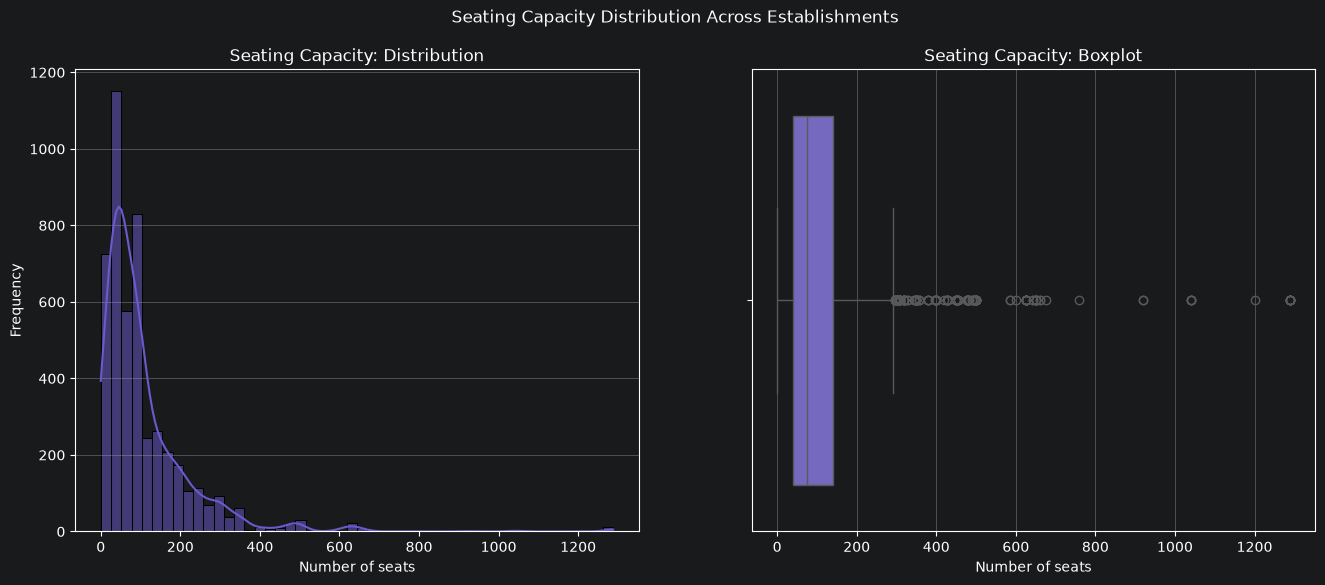

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(
    data=df,
    x='seats',
    bins=50,
    kde=True,
    color='slateblue',
    edgecolor='black',
    ax=axes[0]
)

axes[0].set_title('Seating Capacity: Distribution')
axes[0].set_xlabel('Number of seats')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y')

sns.boxplot(
    data=df,
    x='seats',
    color='slateblue',
    ax=axes[1]
)

axes[1].set_title('Seating Capacity: Boxplot')
axes[1].set_xlabel('Number of seats')
axes[1].grid(axis='x')

plt.suptitle('Seating Capacity Distribution Across Establishments')

plt.show()

The distribution is strongly right-skewed with a long upper tail extending from 500 to 1,288 seats.

**Hypothesis:** Extreme seating capacity values (>700 seats) reflect large banquet halls, food malls, or stadium venues. To test this, the 10 establishments with the highest reported seating capacities were examined.

In [12]:
display(df[['name', 'category', 'seats']].sort_values(by='seats', ascending=False).head(10))

,name,category,seats
6641,One Price Coffee,кофейня,1288
6524,Ян Примус,ресторан,1288
6684,Пивной ресторан,"бар,паб",1288
6658,ГудБар,"бар,паб",1288
6771,Точка,кафе,1288
6574,Мюнгер,пиццерия,1288
6690,Японская кухня,ресторан,1288
6838,Alternative coffee,кофейня,1288
6518,DelonixCafe,ресторан,1288
6808,Яндекс Лавка,ресторан,1288


**Hypothesis refuted, a potential technical parsing artifact identified.** The top records all share the exact value `1288` across small-format coffee shops (*One Price Coffee*, *Alternative coffee*), neighborhood cafes, and dark kitchens (*Yandex Lavka*). This pattern suggests a potential upstream scraping or parsing error, whereby the total seating capacity of a shopping mall or food court may have been incorrectly assigned to individual establishments.

**Mitigation Rule.** Values above 700 seats that occur more than once in the dataset are treated as potential data quality issues and replaced with `NaN`. The threshold was selected based on the extreme values observed in the boxplot. All other attributes of the affected establishments are preserved.

In [13]:
seat_counts = df['seats'].value_counts()

huge_dupes = seat_counts[(seat_counts.index > 700) & (seat_counts > 1)].index
mask_huge_dupes = df['seats'].isin(huge_dupes)

df.loc[mask_huge_dupes, 'seats'] = np.nan

display(df[['name', 'category', 'seats']].sort_values(by='seats', ascending=False).head(10))

,name,category,seats
4231,РестоБар Argomento,столовая,1200
5486,Дом,кафе,760
7987,Ресторан,ресторан,675
2913,Хаус бар,"бар,паб",660
2901,Ресторан Тройка,"бар,паб",660
5738,Университетское,кофейня,650
5758,Шоколадница,кофейня,650
5655,The Fox Pub,"бар,паб",650
5720,Ресторан китайской кухни Чуаньюй,ресторан,650
5835,Lyanson’s coffee,кафе,650


After scrubbing repeated extreme artifacts, the top capacity records represent plausible large-scale restaurants, bars, and dining halls.

In [14]:
display(df.groupby('category')['seats'].describe())

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
"бар,паб",464.0,115.829741,110.045519,0.0,48.0,81.0,143.75,660.0
булочная,148.0,89.385135,97.685844,0.0,25.0,50.0,120.0,625.0
быстрое питание,348.0,96.186782,94.016352,0.0,27.25,65.0,136.25,500.0
кафе,1213.0,93.947238,101.533858,0.0,35.0,60.0,116.0,760.0
кофейня,748.0,106.811497,107.360198,0.0,40.0,80.0,144.0,650.0
пиццерия,426.0,91.694836,96.320059,0.0,30.0,53.5,120.0,625.0
ресторан,1264.0,118.179589,105.186334,0.0,48.0,86.0,150.0,675.0
столовая,164.0,99.75,122.951453,0.0,40.0,75.5,117.0,1200.0


Even after potential artifact removal, category-level medians appear elevated (e.g., 80 seats for coffee shops, 50 seats for bakeries).

**Hypothesis.** Missing values in `seats` occur disproportionately among smaller independent venues or specific categories (MNAR mechanism).

In [15]:
df['seats_missing'] = df['seats'].isna()

display(df.groupby('category')['seats_missing']
      .mean()
      .sort_values(ascending=False))

display(df.groupby('chain')['seats_missing']
      .mean()
      .sort_values(ascending=False))

df = df.drop(columns=['seats_missing'])

category
кафе               0.489478
столовая           0.479365
кофейня            0.470630
быстрое питание    0.422886
булочная           0.421875
бар,паб            0.393464
ресторан           0.380696
пиццерия           0.327014
Name: seats_missing, dtype: float64

chain
0    0.45026
1    0.40156
Name: seats_missing, dtype: float64

**Hypothesis refuted.** Missingness rates across categories (32.7% to 48.9%) and chain statuses (40.2% vs. 45.0%) do not exhibit an extreme structural skew that would confirm a strict MNAR mechanism.

#### Average Bill (middle_avg_bill)

In [16]:
print(f"\nNumber of establishments with a zero average bill: {df[df['middle_avg_bill'] == 0].shape[0]}")

print('\nEstablishments with a zero average bill:')
display(df[df['middle_avg_bill'] == 0])

print('\nEstablishments with the highest average bill:')
display(df.sort_values(by='middle_avg_bill', ascending=False).head())


Number of establishments with a zero average bill: 1

Establishments with a zero average bill:


,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
3688,502d91289bc5470eabd77fd77cc79821,Кофемания,кофейня,"Москва, улица Новый Арбат, 19",Центральный административный округ,"ежедневно, круглосуточно",4.5,1,200,высокие,Средний счёт:от 0 ₽,0.0,NaN



Establishments with the highest average bill:


,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
7177,07b4e95afe8b4d299f823dc4f9de6df5,Кафе,ресторан,"Москва, Каширское шоссе, 23, стр. 2",Южный административный округ,"ежедневно, круглосуточно",4.1,0,100,высокие,Средний счёт:20000–50000 ₽,35000.0,NaN
730,8ce8586978ff40d59375f65ef90757c2,Чойхона,"бар,паб","Москва, Дмитровское шоссе, 95А",Северный административный округ,"ежедневно, 10:00–23:00",4.4,0,49,высокие,Средний счёт:5000–17000 ₽,11000.0,NaN
5481,b73dde11d59e435d98d3004a614a9c3f,Гости,ресторан,"Москва, шоссе Энтузиастов, 52",Восточный административный округ,"пн,вс 18:00–22:30",4.1,0,<NA>,высокие,Средний счёт:5000–15000 ₽,10000.0,NaN
3882,0f7f31a95ed4459fa5f8de9a7da7b8ad,White Rabbit,ресторан,"Москва, Смоленская площадь, 3",Центральный административный округ,"ежедневно, 12:00–00:00",4.9,0,150,высокие,Средний счёт:7000–7500 ₽,7250.0,NaN
3487,4717553a4ce541c48cb62bb9f87e8fc6,800°с Contemporary Steak,ресторан,"Москва, Большой Патриарший переулок, 6, стр. 1",Центральный административный округ,"ежедневно, 09:00–23:30",4.7,0,75,высокие,Средний счёт:6000–8000 ₽,7000.0,NaN


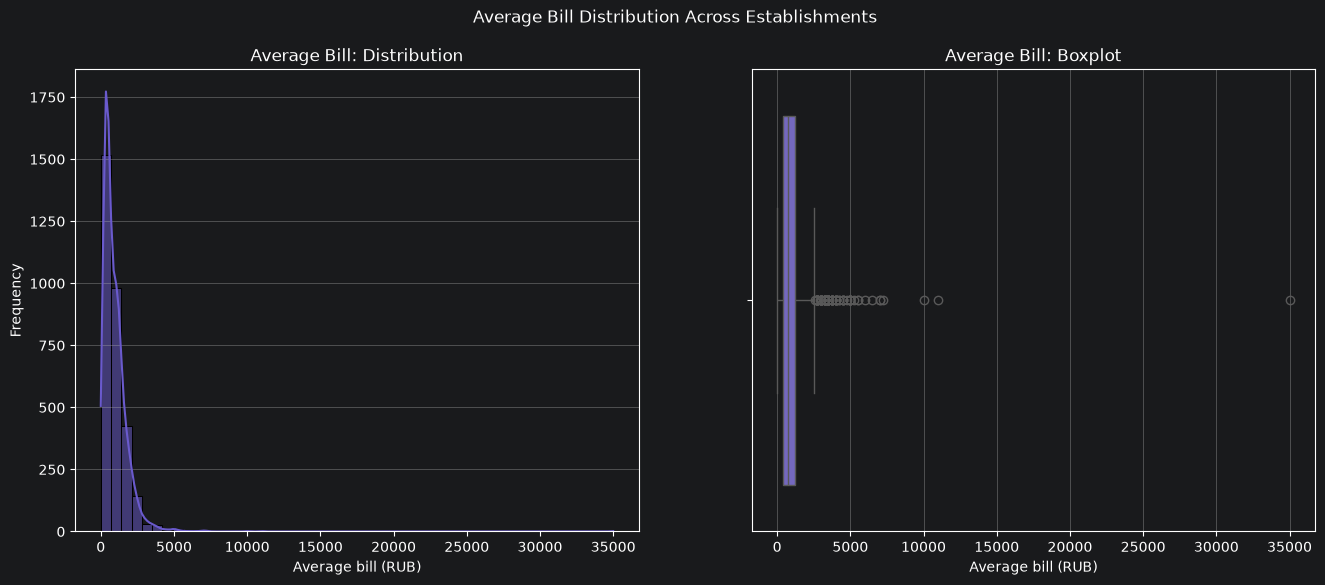

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(
    data=df,
    x='middle_avg_bill',
    color='slateblue',
    bins=50,
    edgecolor='black',
    ax=axes[0],
    kde=True
)

axes[0].set_title('Average Bill: Distribution')
axes[0].set_xlabel('Average bill (RUB)')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y')

sns.boxplot(
    data=df,
    x='middle_avg_bill',
    color='slateblue',
    ax=axes[1]
)

axes[1].set_title('Average Bill: Boxplot')
axes[1].set_xlabel('Average bill (RUB)')
axes[1].grid(axis='x')

plt.suptitle('Average Bill Distribution Across Establishments')

plt.show()

- Among the 3,149 establishments with available average bill data, the interquartile range (IQR) is 375–1,250 RUB, with a median of 750 RUB. The mean is higher at 958 RUB, with a standard deviation of approximately 1,010 RUB, indicating substantial variability and a right-skewed distribution. This pattern may be partly explained by high-end restaurants. One establishment stands out with a reported average bill of 35,000 RUB; the original source lists the price range as "Average bill: 20,000–50,000 RUB."
- One record contains `middle_avg_bill == 0.0` for *Coffeemania* on Novy Arbat. The source description, "Average bill: from 0 RUB," was interpreted as a numeric value of `0.0`. Since this is an isolated case, it is unlikely to materially affect aggregate statistics such as district-level medians.

No values are removed or modified. Although the reported average bill of 35,000 RUB is extreme relative to the overall distribution, it is plausible for a high-end establishment and is supported by the source price range. The zero value is retained as well, with its parsing limitation documented.

---

### 4.4 Missing Values Analysis and Imputation Strategy

In [18]:
display(df.isna().sum())

id                      0
name                    0
category                0
address                 0
district                0
hours                 535
rating                  0
chain                   0
seats                3627
price                5087
avg_bill             4586
middle_avg_bill      5253
middle_coffee_cup    7867
dtype: int64

In [19]:
display(df.isna().sum() / df.shape[0])

id                   0.000000
name                 0.000000
category             0.000000
address              0.000000
district             0.000000
hours                0.063675
rating               0.000000
chain                0.000000
seats                0.431683
price                0.605451
avg_bill             0.545822
middle_avg_bill      0.625208
middle_coffee_cup    0.936325
dtype: float64

**Missingness Overview:**
* **Extreme missingness (~93.6%):** `middle_coffee_cup` (7,871 missing).
* **High missingness (43.0%–62.5%):** `middle_avg_bill` (62.5%), `price` (60.6%), `avg_bill` (54.6%), and `seats` (43.0%).
* **Low missingness (6.4%):** `hours` (536 missing).

To investigate potential patterns in missing data, two helper functions are defined. The `missing_rate` function calculates the percentage of missing values within specified subgroups, while `analyze_missing_by_feature` automates this calculation across multiple columns for a given grouping feature. This approach helps identify differences in missing-value rates across establishment categories and other subgroups.

In [20]:
def missing_rate(group_attr, target_attr):
    return df.groupby(group_attr)[target_attr].apply(lambda x: x.isna().mean() * 100).sort_values(ascending=False)

def analyze_missing_by_feature(feature, columns):
    for col in columns:
        print(f'\nMissing values in {col}:')
        display(missing_rate(feature, col))

analyze_columns = ['hours', 'seats', 'price', 'avg_bill', 'middle_avg_bill', 'middle_coffee_cup']

#### 4.4.1 Missingness by Venue Category

In [21]:
analyze_missing_by_feature('category', analyze_columns)


Missing values in hours:


category
кафе               15.740741
быстрое питание     5.472637
ресторан            3.625674
столовая            2.857143
булочная            2.734375
бар,паб             2.352941
кофейня             1.061571
пиццерия            0.789889
Name: hours, dtype: float64


Missing values in seats:


category
кафе               48.947811
столовая           47.936508
кофейня            47.062987
быстрое питание    42.288557
булочная           42.187500
бар,паб            39.346405
ресторан           38.069574
пиццерия           32.701422
Name: seats, dtype: float64


Missing values in price:


...

category
булочная           79.296875
кафе               70.622896
быстрое питание    60.530680
ресторан           49.044586
кофейня            48.973815
столовая           42.539683
пиццерия           36.808847
бар,паб            36.601307
Name: avg_bill, dtype: float64


Missing values in middle_avg_bill:


category
кофейня            85.845718
булочная           79.296875
кафе               70.791246
быстрое питание    60.696517
бар,паб            54.379085
ресторан           49.044586
столовая           42.539683
пиццерия           37.598736
Name: middle_avg_bill, dtype: float64


Missing values in middle_coffee_cup:


category
булочная           100.000000
столовая           100.000000
ресторан           100.000000
быстрое питание     99.834163
кафе                99.831650
пиццерия            99.526066
бар,паб             99.215686
кофейня             63.128096
Name: middle_coffee_cup, dtype: float64

* **`hours`:** Missingness is concentrated in the `кафе` (cafe) category (15.8%), compared to $\le\$5.5% in all other formats.
* **`seats`:** High missingness across all categories (32.5% to 48.8%).
* **`price` & `avg_bill`:** Highest missingness in bakeries (`булочная`, 84.0% and 79.3%) and cafes (`кафе`, 73.4% and 70.6%).
* **`middle_avg_bill`:** Highest missingness in coffee shops (`кофейня`, 85.8%) and bakeries (79.3%).
* **`middle_coffee_cup`:** Nearly 100% missing in all categories *except* coffee shops (`кофейня`, 63.1% missing), confirming that cappuccino pricing is a format-specific metric.

#### 4.4.2 Missingness by Administrative District

In [22]:
analyze_missing_by_feature('district', analyze_columns)


Missing values in hours:


district
Юго-Восточный административный округ       11.904762
Северо-Западный административный округ      9.779951
Восточный административный округ            9.398496
Юго-Западный административный округ         8.321580
Западный административный округ             7.647059
Южный административный округ                7.286996
Северо-Восточный административный округ     6.853933
Северный административный округ             6.013363
Центральный административный округ          1.382694
Name: hours, dtype: float64


Missing values in seats:


district
Юго-Восточный административный округ       50.980392
Восточный административный округ           48.120301
Центральный административный округ         47.457627
Западный административный округ            45.411765
Северо-Восточный административный округ    43.370787
Юго-Западный административный округ        36.812412
Южный административный округ               36.434978
Северный административный округ            34.966592
Северо-Западный административный округ     34.963325
Name: seats, dtype: float64


Missing values in price:


...

district
Юго-Восточный административный округ       66.946779
Восточный административный округ           61.152882
Юго-Западный административный округ        61.071932
Северо-Восточный административный округ    58.651685
Южный административный округ               58.071749
Западный административный округ            57.411765
Северо-Западный административный округ     54.767726
Северный административный округ            54.008909
Центральный административный округ         42.372881
Name: avg_bill, dtype: float64


Missing values in middle_avg_bill:


district
Юго-Восточный административный округ       72.829132
Восточный административный округ           67.418546
Юго-Западный административный округ        66.854725
Северо-Восточный административный округ    66.179775
Южный административный округ               64.798206
Северный административный округ            64.142539
Западный административный округ            64.000000
Северо-Западный административный округ     61.613692
Центральный административный округ         52.720785
Name: middle_avg_bill, dtype: float64


Missing values in middle_coffee_cup:


district
Юго-Восточный административный округ       95.098039
Юго-Западный административный округ        95.063470
Южный административный округ               94.843049
Восточный административный округ           94.736842
Северо-Западный административный округ     94.132029
Западный административный округ            94.117647
Северо-Восточный административный округ    93.258427
Центральный административный округ         92.595897
Северный административный округ            91.425390
Name: middle_coffee_cup, dtype: float64

Across administrative districts, missingness rates are broadly comparable, with the South-Eastern Administrative District (YUVAO) exhibiting the highest proportion of missing records across operational and financial columns, and the Central District (CAO) showing the most complete coverage.

#### 4.4.3 Missingness by Chain Affiliation

In [23]:
analyze_missing_by_feature('chain', analyze_columns)


Missing values in hours:


chain
0    8.062344
1    3.619345
Name: hours, dtype: float64


Missing values in seats:


chain
0    45.025977
1    40.156006
Name: seats, dtype: float64


Missing values in price:


...

chain
0    54.762363
1    54.290172
Name: avg_bill, dtype: float64


Missing values in middle_avg_bill:


chain
1    62.995320
0    62.228209
Name: middle_avg_bill, dtype: float64


Missing values in middle_coffee_cup:


chain
0    94.766211
1    91.794072
Name: middle_coffee_cup, dtype: float64

Chain and independent venues display very similar missingness profiles across financial metrics, indicating no systematic reporting bias by ownership structure.

#### 4.4.4 Missingness by Price Tier

In [24]:
# Fill missing values with a placeholder before analysis
df['price_filled'] = df['price'].fillna('unknown')

analyze_columns.remove('price')

analyze_missing_by_feature('chain', analyze_columns)

df = df.drop(columns=['price_filled'])


Missing values in hours:


chain
0    8.062344
1    3.619345
Name: hours, dtype: float64


Missing values in seats:


chain
0    45.025977
1    40.156006
Name: seats, dtype: float64


Missing values in avg_bill:


chain
0    54.762363
1    54.290172
Name: avg_bill, dtype: float64


Missing values in middle_avg_bill:


chain
1    62.995320
0    62.228209
Name: middle_avg_bill, dtype: float64


Missing values in middle_coffee_cup:


chain
0    94.766211
1    91.794072
Name: middle_coffee_cup, dtype: float64

The analysis of missing values across price categories, including the `unknown` group, revealed the following patterns:

- Missing values in `hours`, `avg_bill`, and `middle_avg_bill` are substantially more prevalent among establishments with an unknown price category.
- The `seats` feature has a high proportion of missing values (33–46%) across all price segments, indicating that incomplete seating capacity data is a widespread issue rather than one specific to a particular price category.
- Missingness in `middle_coffee_cup` varies considerably across price categories. All categories except the low-price segment exhibit critically high missing-value rates, making this feature of limited informational value for establishments in the more expensive segments.

Grouping by `price` (with missing tiers labeled `'unknown'`) reveals a striking anomaly: `middle_coffee_cup` is missing for >89% of mid-to-high-tier venues, but only 63.5% missing in the low-price segment (`низкие`).

**Hypothesis.** Missingness in cappuccino price (`middle_coffee_cup`) is structurally tied to venue format, whereas the low-price segment (`низкие`) is heavily dominated by coffee shops.

In [25]:
df[df['price'] == 'низкие']['category'].value_counts().head()

category
кофейня            68
кафе               26
быстрое питание    22
ресторан           21
столовая           10
Name: count, dtype: int64

**Hypothesis confirmed.** Coffee shops (`кофейня`, 68 venues) are the single largest category within the low-price tier.

#### 4.4.5 Structural Hierarchy of Financial Attributes

Since `price`, `avg_bill`, `middle_avg_bill`, and `middle_coffee_cup` all originate from rest_price.csv, the analysis examines whether missing values in these features tend to occur together.

In [26]:
df['is_middle_coffee_cup'] = df['middle_coffee_cup'].isna()
df['is_middle_avg_bill'] = df['middle_avg_bill'].isna()
df['is_price'] = df['price'].isna()

In [27]:
display(df.groupby(df['avg_bill'].isna())['is_price'].mean() * 100)

avg_bill
False    19.47065
True     94.72307
Name: is_price, dtype: float64

When `avg_bill` is available, `price` is missing in only 19.5% of cases, compared with 94.7% when `avg_bill` is missing. The next step is to examine whether the same pattern holds when missingness in `price` is assessed against the availability of `middle_avg_bill`.

In [28]:
display(df.groupby(df['middle_avg_bill'].isna())['is_price'].mean() * 100)

middle_avg_bill
False    14.925373
True     87.892633
Name: is_price, dtype: float64

Notably, **14.9% of venues with a known numeric `middle_avg_bill` lack a qualitative `price` tier**, creating a direct opportunity for deterministic recovery.

Next, the availability of `middle_avg_bill` and `middle_coffee_cup` is examined in relation to the source text in `avg_bill` to assess the completeness of the parsing process.

In [29]:
display(df.groupby(df['avg_bill'].isna())['is_middle_avg_bill'].mean() * 100)

avg_bill
False     17.479036
True     100.000000
Name: is_middle_avg_bill, dtype: float64

In [30]:
raw_bill_rows = df[df['avg_bill'].str.contains('Средний счёт', case=False, na=False)]

print(f"Total number of lines in the text that mention an average bill: {len(raw_bill_rows)}")
print(f"Total number of filled values in 'middle_avg_bill': {df['middle_avg_bill'].count()}")

Total number of lines in the text that mention an average bill: 3149
Total number of filled values in 'middle_avg_bill': 3149


In [31]:
display(df.groupby(df['avg_bill'].isna())['is_middle_coffee_cup'].mean() * 100)

avg_bill
False     85.980084
True     100.000000
Name: is_middle_coffee_cup, dtype: float64

In [32]:
raw_coffee_rows = df[df['avg_bill'].str.contains('капучино', case=False, na=False)]

print(f"Total number of lines in the text that mention cappuccino: {len(raw_coffee_rows)}")
print(f"Total number of filled values in 'middle_coffee_cup': {df['middle_coffee_cup'].count()}")

Total number of lines in the text that mention cappuccino: 535
Total number of filled values in 'middle_coffee_cup': 535


In [33]:
df = df.drop(columns=['is_middle_coffee_cup', 'is_middle_avg_bill', 'is_price'])

**Parsing Audit Confirmed.**
* Every single record containing `"Средний счёт"` in `avg_bill` (3,149 rows) was parsed into `middle_avg_bill`.
* Every single record containing `"капучино"` in `avg_bill` (535 rows) was parsed into `middle_coffee_cup`.
* Whenever `avg_bill` is `NaN`, both numeric columns are 100% `NaN`. Thus, `avg_bill` is the root financial string from which numeric metrics are derived.

#### 4.4.6 Imputation of Recoverable `price` Tiers

While missing values in `hours`, `seats`, `avg_bill`, `middle_avg_bill`, and `middle_coffee_cup` are left unimputed to avoid distorting their distributions, missing `price` categories can be reconstructed for establishments with valid numeric values in `middle_avg_bill`.

* **Step 1:** Compute empirical interquartile boundaries (`25%`, `50%`, `75%`) of `middle_avg_bill` across known price categories:

In [34]:
display(df.groupby('price')['middle_avg_bill'].describe()[['25%', '50%', '75%']])

,25%,50%,75%
price,,,
высокие,1750.0,2000.0,2500.0
выше среднего,1250.0,1250.0,1500.0
низкие,150.0,180.0,250.0
средние,350.0,500.0,850.0


* **Step 2:** Define midpoint cutoffs between adjacent quartiles (`<300` RUB = `низкие`, `300–999` RUB = `средние`, `1000–1599` RUB = `выше среднего`, `>=1600` RUB = `высокие`) and apply vectorized binning via `pd.cut()` to recover missing `price` labels. Remaining records without bill data are explicitly categorized as `'unknown'`:

In [35]:
def get_price_category(bill):
    if bill < 300:
        return 'низкие'
    elif 300 <= bill < 1000:
        return 'средние'
    elif 1000 <= bill < 1600:
        return 'выше среднего'
    else:
        return 'высокие'

mask_restorable = df['price'].isna() & df['middle_avg_bill'].notna()

df.loc[mask_restorable, 'price'] = pd.cut(
    df.loc[mask_restorable, 'middle_avg_bill'],
    bins=[-float('inf'), 300, 1000, 1600, float('inf')],
    labels=['низкие', 'средние', 'выше среднего', 'высокие'],
    right=False
)

df['price'] = df['price'].fillna('unknown')

print(f"Missing values in 'price' after imputation: {df['price'].isna().sum()}")

Missing values in 'price' after imputation: 0


---

### 4.5 Data Cleaning Summary

1. **Memory & Type Optimization:** Downcast `rating` (`float32`), `chain` (`int8`), and `seats` (nullable `Int16`), ensuring clean schema semantics.
2. **Entity Deduplication & Text Normalization:** Confirmed zero exact/ID duplicates, resolved 4 implicit name+address duplicate pairs (retaining 8,402 unique venues), and standardized `hours` strings across 1,307 unique schedule patterns.
3. **Outlier & Artifact Scrubbing:** Identified and removed a mall food-court parsing artifact (`seats == 1288` repeated across small tenants) by setting repeated capacities $>700$ to `NaN`.
4. **Evidence-Based Missingness Handling:**
   * **Recovered:** ~20% of missing `price` tiers were deterministically reconstructed from known `middle_avg_bill` values using empirical quartile boundaries.
   * **Preserved as `NaN`:** `hours` (MAR, 6.4%—modal imputation would falsely turn cafes without schedules into 24/7 venues), `seats` (43.0%), and raw financial metrics (`avg_bill`, `middle_avg_bill`, `middle_coffee_cup`) were left un-imputed to prevent artificial variance suppression and synthetic correlation artifacts.

---

## 5. Feature Engineering

To assess whether 24/7 operation is associated with venue ratings or establishment format, a binary indicator, `is_24_7`, is created:

- `True` if the venue operates 24 hours a day, 7 days a week.
- `False` otherwise, including venues with 24-hour operating schedules limited to certain days and venues with missing schedule information.

First, all normalized `hours` strings containing the substring `'круглосуточно'` (open 24 hours) are inspected to avoid false positives from venues that operate overnight only on Fridays or Saturdays.

In [36]:
suspicious_hours = df[df['hours'].str.contains('круглосуточно', na=False)]['hours'].unique()

print("Identified variations of 24/7 operation:")
for h in suspicious_hours:
    print(f"- {h}")

Identified variations of 24/7 operation:
- ежедневно, круглосуточно
- пн 00:01–12:00, перерыв 12:00–13:30; вт-чт 13:30–12:00; пт 13:30–00:00; сб,вс круглосуточно
- вт-вс круглосуточно
- сб круглосуточно
- пт-вс круглосуточно
- пн,ср,чт,пт,сб,вс круглосуточно
- пн 10:00–00:00; вт-сб круглосуточно; вс 00:00–23:00
- пн-чт 07:30–23:00; пт 07:30–00:00; сб круглосуточно; вс 00:00–23:00
- пн круглосуточно; вт-чт 12:00–00:00; пт 12:00–02:00; сб 11:00–02:00; вс 14:00–00:00
- пн-чт 08:00–23:00; пт,сб круглосуточно; вс 08:00–23:00
- пн-ср 07:00–23:00; чт 07:00–00:00; пт,сб круглосуточно; вс 00:00–23:00
- пн-чт 08:00–23:00; пт 08:00–00:00; сб круглосуточно; вс 00:00–23:00
- пн 08:00–23:00; вт-пт 08:00–00:00; сб круглосуточно; вс 00:00–23:00
- пн-ср 09:00–00:00; чт-вс круглосуточно
- пн-чт круглосуточно; пт 00:00–05:00, перерыв 05:00–07:00; сб 07:00–05:00; вс 07:00–00:00
- пн-чт 11:00–23:00; пт 11:00–00:00; сб круглосуточно; вс 00:00–23:00
- пн,вт 08:00–22:00; ср,чт 08:00–23:00; пт,сб круглосуточно

The inspection confirms that partial schedules (e.g., `'пт,сб круглосуточно'` and `'сб круглосуточно'`) indicate 24-hour operation limited to specific days. Only the exact string `'ежедневно, круглосуточно'` indicates continuous 24/7 operation. Accordingly, `is_24_7` is created using an exact string match.

In [37]:
df['is_24_7'] = (df['hours'] == 'ежедневно, круглосуточно')

print(f"Number of establishments with 24/7 operating hours: {df['is_24_7'].sum()}")

Number of establishments with 24/7 operating hours: 730


Exactly 730 venues (8.7% of the cleaned dataset) operate on a true 24/7 schedule.

---

## 6. Exploratory Data Analysis

### 6.1 Venue Category Distribution

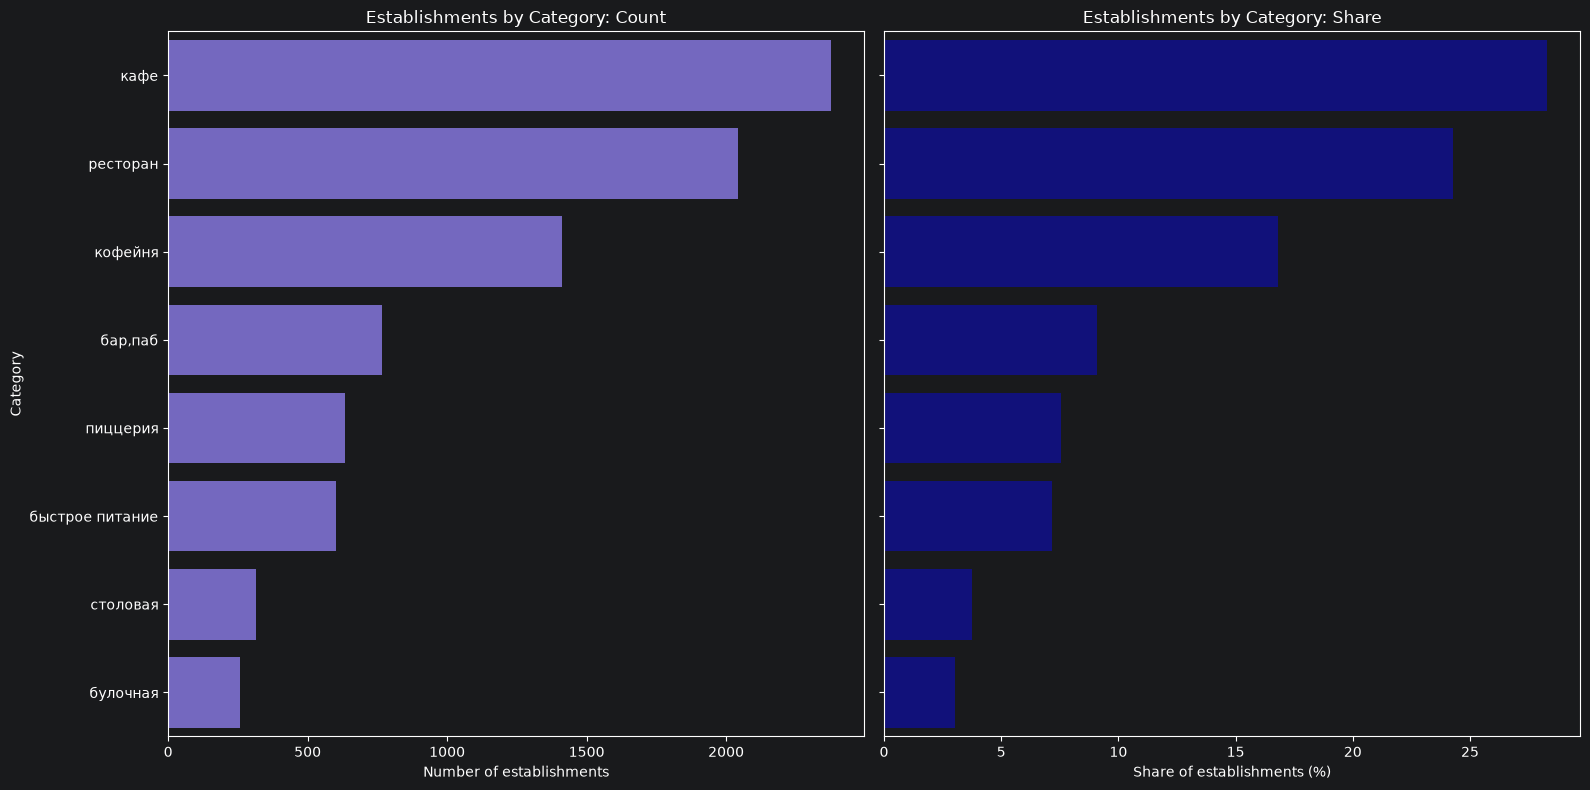

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

counts = df['category'].value_counts()
percents = df['category'].value_counts(normalize=True) * 100

sns.barplot(
    x=counts.values,
    y=counts.index,
    color='slateblue',
    orient='h',
    ax=axes[0]
)

axes[0].set_title('Establishments by Category: Count')
axes[0].set_xlabel('Number of establishments')
axes[0].set_ylabel('Category')

sns.barplot(
    x=percents.values,
    y=percents.index,
    color='darkblue',
    orient='h',
    ax=axes[1]
)

axes[1].set_title('Establishments by Category: Share')
axes[1].set_xlabel('Share of establishments (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

**Insight.**
* **Market Leaders:** Cafes (`кафе`, >25% share) and full-service restaurants (`ресторан`, ~24% share) dominate the landscape, jointly representing nearly half of all food service establishments in Moscow.
* **Mid-Tier Formats:** Coffee shops (`кофейня`), bars/pubs (`бар,паб`), pizzerias (`пиццерия`), and fast-food venues (`быстрое питание`) form a substantial secondary layer.
* **Niche Formats:** Canteens (`столовая`, ~3.5%) and bakeries (`булочная`, ~3.0%) account for the smallest share of active locations.

---

### 6.2 Geographic Distribution and Central District (CAO) Profile

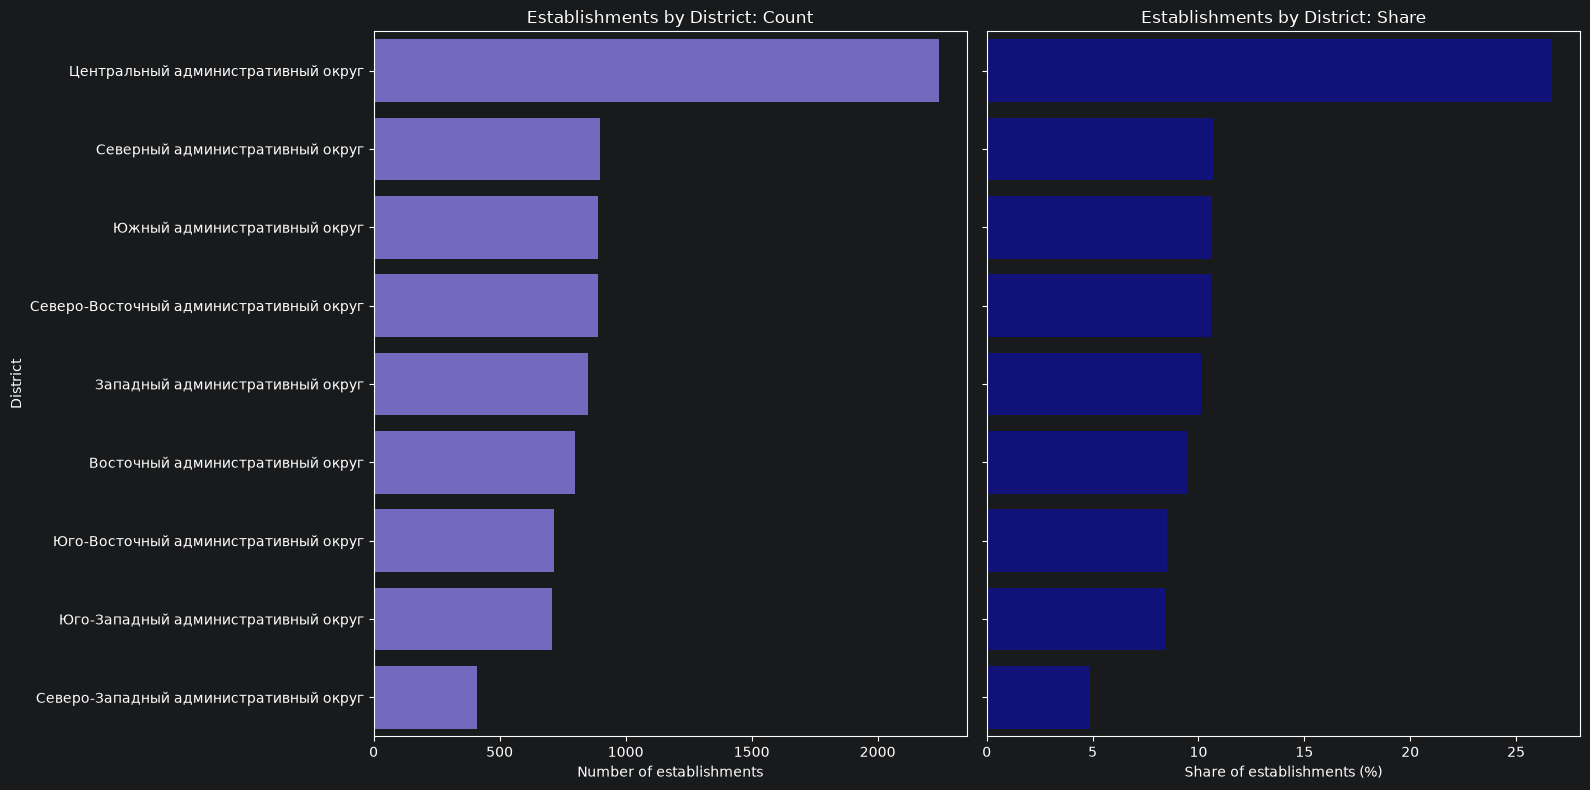

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

counts = df['district'].value_counts()
percents = df['district'].value_counts(normalize=True) * 100

sns.barplot(
    x=counts.values,
    y=counts.index,
    color='slateblue',
    orient='h',
    ax=axes[0]
)

axes[0].set_title('Establishments by District: Count')
axes[0].set_xlabel('Number of establishments')
axes[0].set_ylabel('District')

sns.barplot(
    x=percents.values,
    y=percents.index,
    color='darkblue',
    orient='h',
    ax=axes[1]
)

axes[1].set_title('Establishments by District: Share')
axes[1].set_xlabel('Share of establishments (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

**Insight.**
* **Hyper-Concentration in the Center:** The Central Administrative District (CAO) hosts over 25% of all venues in Moscow, more than 2.5 times the volume of any other district, reflecting intense tourist foot traffic and business-center density.
* **Balanced Secondary Ring:** Most outer administrative districts (YUAO, SVAO, ZAO, SAO, etc.) cluster within a narrow band of 8%–11% market share each.
* **Under-Penetrated Periphery:** The North-Western Administrative District (SZAO) accounts for only ~5% of citywide venues, representing either lower commercial density or an under-saturated local market.

To examine how the mix of establishment categories in the city center differs from the citywide distribution, the category distribution within the Central Administrative District (CAO) is analyzed separately:

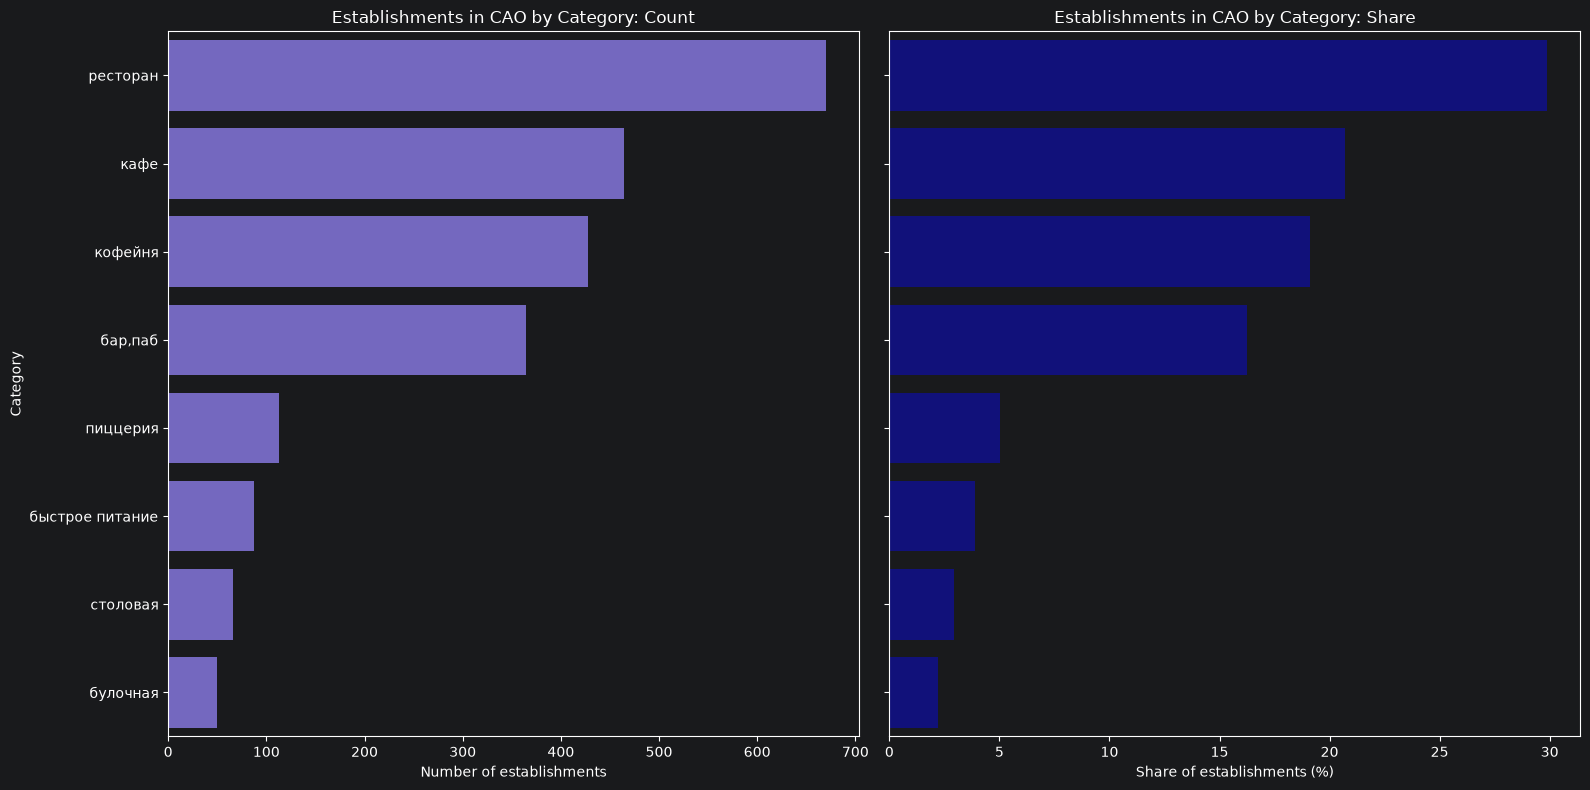

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

counts = df[df['district'] == 'Центральный административный округ']['category'].value_counts()
percents = df[df['district'] == 'Центральный административный округ']['category'].value_counts(normalize=True) * 100

sns.barplot(
    x=counts.values,
    y=counts.index,
    color='slateblue',
    orient='h',
    ax=axes[0]
)

axes[0].set_title('Establishments in CAO by Category: Count')
axes[0].set_xlabel('Number of establishments')
axes[0].set_ylabel('Category')

sns.barplot(
    x=percents.values,
    y=percents.index,
    color='darkblue',
    orient='h',
    ax=axes[1]
)

axes[1].set_title('Establishments in CAO by Category: Share')
axes[1].set_xlabel('Share of establishments (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

**Insight.**
* **Shift Toward Full-Service Dining & Nightlife:** Unlike the broader city (where cafes lead), **restaurants** are the #1 format in CAO (~30% share vs. ~24% citywide). Furthermore, **bars and pubs** account for ~16% of CAO venues (vs. ~10% citywide), underscoring the center's role as Moscow's primary dining and nightlife hub.
* **Compression of Budget Formats:** Fast-food outlets (~4%), canteens (~3%), and bakeries (~2%) occupy a significantly smaller footprint in CAO, likely squeezed out by high commercial lease rates.

---

### 6.3 Chain vs. Independent Market Penetration

The total number of independent establishments (`chain == 0`) is compared with the number of chain establishments (`chain == 1`), followed by an analysis of chain prevalence within each establishment category.

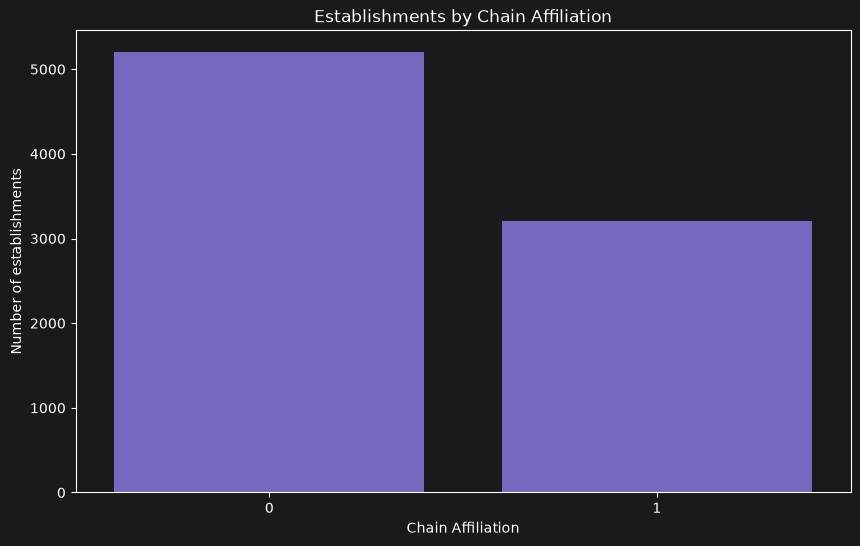

In [41]:
plt.figure(figsize=(10, 6))

counts = df['chain'].value_counts()

sns.barplot(
    x=counts.index,
    y=counts.values,
    color='slateblue'
)

plt.title('Establishments by Chain Affiliation')
plt.xlabel('Chain Affiliation')
plt.ylabel('Number of establishments')
plt.show()

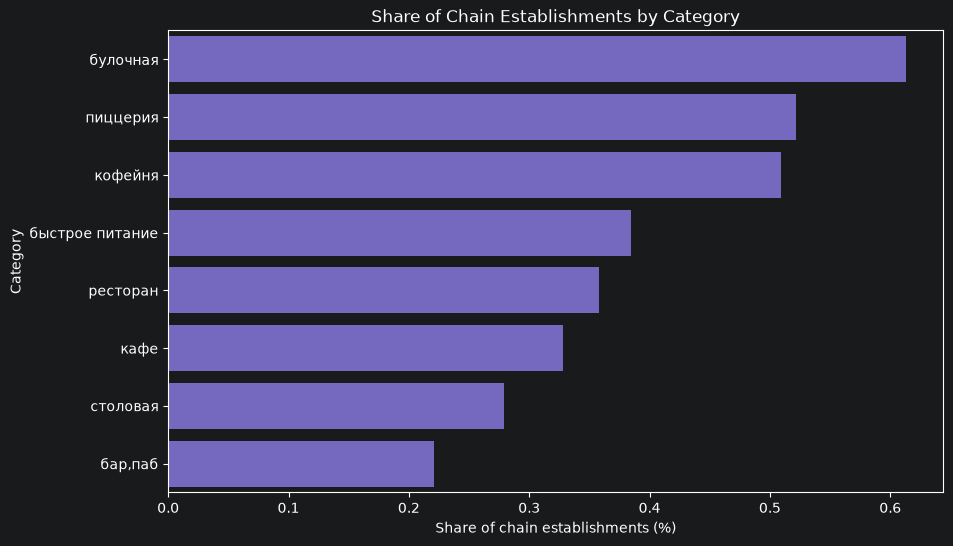

In [42]:
plt.figure(figsize=(10, 6))

share = df.groupby('category')['chain'].mean().sort_values(ascending=False)

sns.barplot(
    x=share.values,
    y=share.index,
    color='slateblue',
    orient='h'
)

plt.title('Share of Chain Establishments by Category')
plt.xlabel('Share of chain establishments (%)')
plt.ylabel('Category')
plt.show()

**Insight.**
* **Overall Market Split:** Independent businesses outnumber chain outlets citywide (~62% independent vs. ~38% chain), demonstrating low barriers to entry for single-location operators.
* **Format Standardization Drives Chain Share:** Bakeries (`булочная`), pizzerias (`пиццерия`), coffee shops (`кофейня`), and fast-food venues (`быстрое питание`) exhibit the highest chain penetration (40%–60%+). These formats rely on standardized recipes, centralized supply chains, and repeatable counter-service workflows that scale efficiently.
* **Atmosphere & Local Specificity Favor Independents:** Bars/pubs (`бар,паб`) and canteens (`столовая`) have the lowest chain shares. Bars compete on unique concept identity and atmosphere, while canteens often operate as localized institutional or business-center catering units.

---

### 6.4 Seating Capacity Analysis

Following the removal of the `1288` seating-capacity parsing artifact in Section 4.3, the cleaned distribution of `seats` is examined. Category-level medians are compared alongside interquartile-range error bars and missing-value rates.

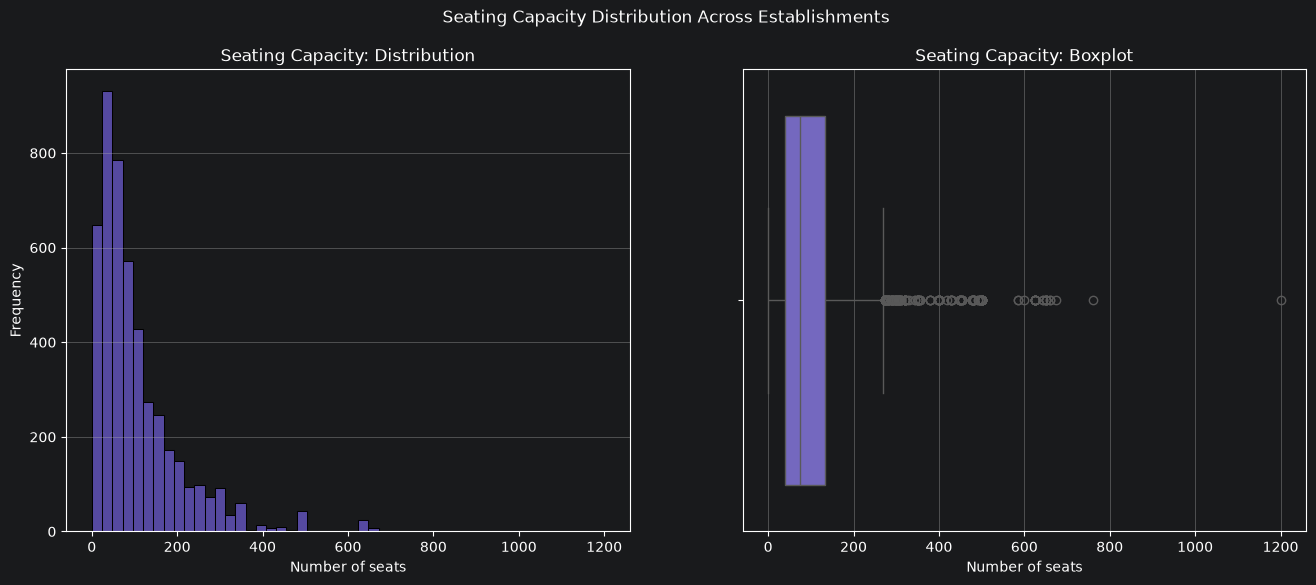

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(
    data=df,
    x='seats',
    bins=50,
    color='slateblue',
    edgecolor='black',
    ax=axes[0]
)

axes[0].set_title('Seating Capacity: Distribution')
axes[0].set_xlabel('Number of seats')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y')

sns.boxplot(
    data=df,
    x='seats',
    color='slateblue',
    ax=axes[1]
)

axes[1].set_title('Seating Capacity: Boxplot')
axes[1].set_xlabel('Number of seats')
axes[1].grid(axis='x')

plt.suptitle('Seating Capacity Distribution Across Establishments')

plt.show()

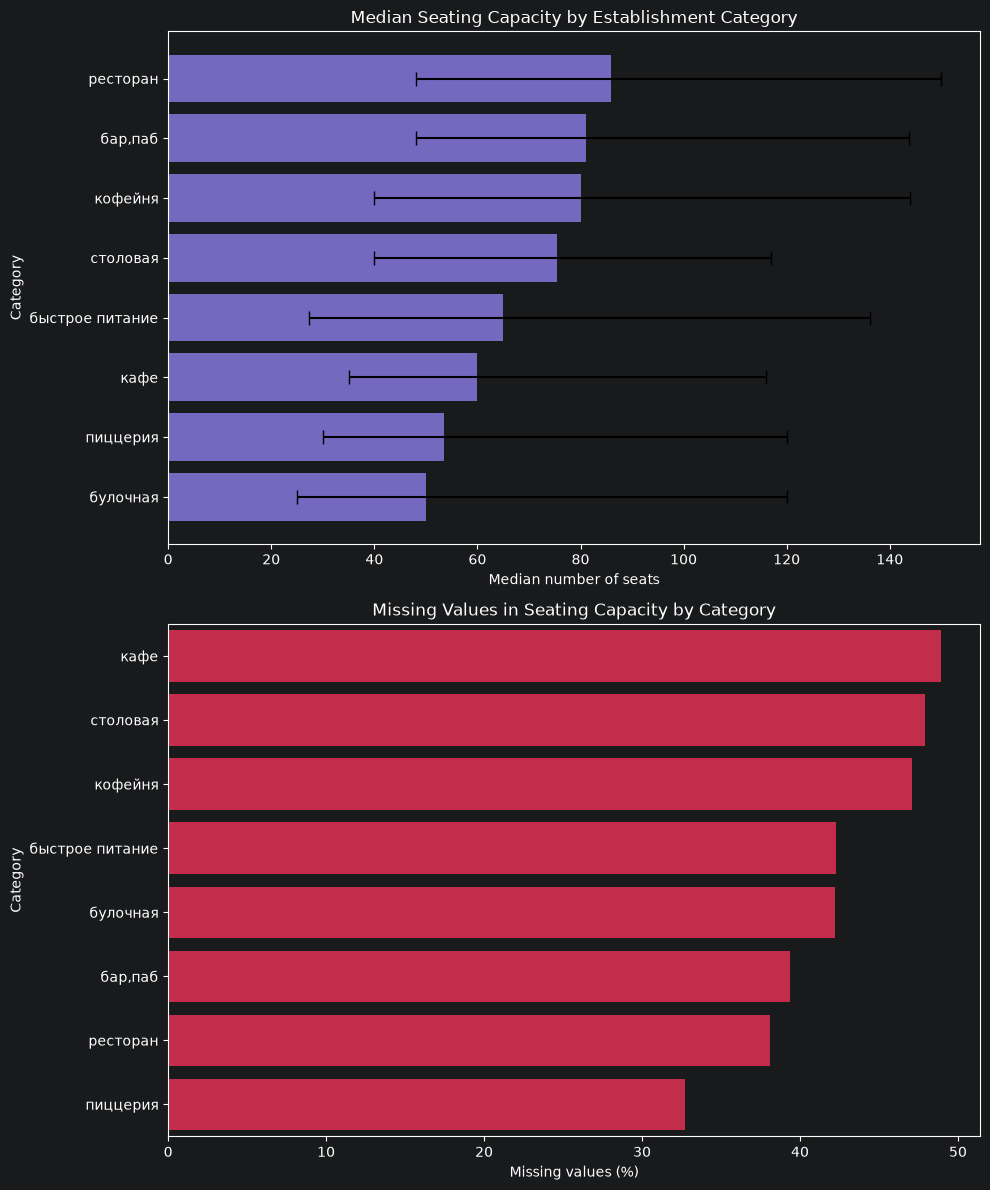

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(10, 12))

seats_stats = ( 
    df.groupby('category')['seats']
    .quantile([0.25, 0.5, 0.75])
    .unstack()
    .reset_index()
    .rename(columns={0.25: 'q1', 0.5: 'median', 0.75: 'q3'})
    .sort_values(by='median', ascending=False)
)

sns.barplot(
    data=seats_stats,
    x='median',
    y='category',
    color='slateblue',
    ax=axes[0]
)

axes[0].errorbar(
    y=range(len(seats_stats)),
    x=seats_stats['median'],
    xerr=[
        seats_stats['median'] - seats_stats['q1'],
        seats_stats['q3'] - seats_stats['median']
    ],
    fmt='none',
    ecolor='black',
    capsize=5,
    elinewidth=1.5
)

axes[0].set_title('Median Seating Capacity by Establishment Category')
axes[0].set_ylabel('Category')
axes[0].set_xlabel('Median number of seats')

missing_share = (
    df.groupby('category')['seats']
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=missing_share.values,
    y=missing_share.index,
    orient='h',
    color='crimson',
    ax=axes[1]
)

axes[1].set_title('Missing Values in Seating Capacity by Category')
axes[1].set_ylabel('Category')
axes[1].set_xlabel('Missing values (%)')

plt.tight_layout()
plt.show()

**Insight.**
* **Compact Formats Dominate:** The cleaned capacity distribution remains right-skewed, with the vast majority of observed venues accommodating fewer than 100 guests.
* **Format Hierarchy:** Among venues reporting capacity, full-service restaurants (`ресторан`, median: 86 seats) and bars/pubs (`бар,паб`, median: 81 seats) are the largest, while pizzerias (53.5 seats) and bakeries (50 seats) are the most compact.
* **Wide Intra-Category Dispersion & Missingness Caveat:** Every category displays a wide interquartile range (black error bars), indicating substantial format flexibility. Because 32.7% to 48.9% of capacity records are missing across categories, these medians describe the *observed subsample* and should be treated as indicative benchmarks rather than rigid architectural requirements.

---

### 6.5 Customer Rating Distribution Across Formats

Before comparing mean ratings across establishment categories, the overall distribution of `rating` across all 8,402 establishments is examined.

In [45]:
display(df['rating'].describe())

count    8402.000000
mean        4.230017
std         0.470320
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

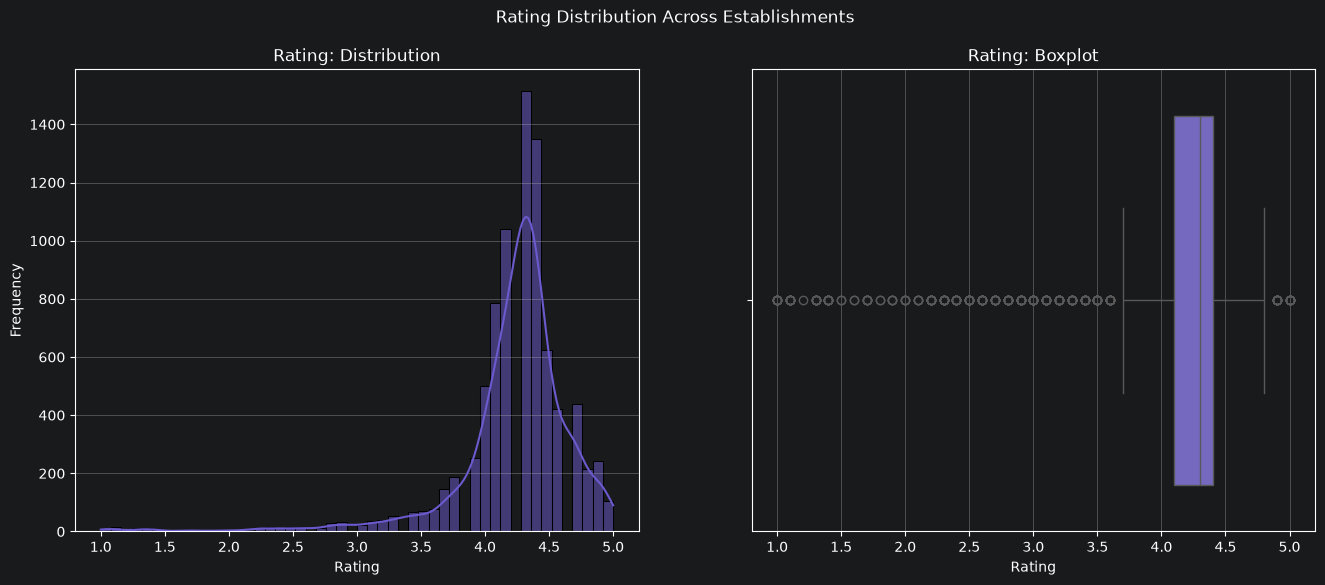

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(
    data=df,
    x='rating',
    bins=50,
    color='slateblue',
    edgecolor='black',
    ax=axes[0],
    kde=True
)

axes[0].set_title('Rating: Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y')

sns.boxplot(
    data=df,
    x='rating',
    color='slateblue',
    ax=axes[1]
)

axes[1].set_title('Rating: Boxplot')
axes[1].set_xlabel('Rating')
axes[1].grid(axis='x')

plt.suptitle('Rating Distribution Across Establishments')

plt.show()

**Insight.**
* **Extreme Left-Skew and Upper-Bound Compression:** User ratings are heavily concentrated between 4.1 and 4.4 (`IQR = 0.30`, `median = 4.30`, `mean = 4.23`, `std = 0.47`), with low-rating outliers trailing down to 1.0.
* **High Sensitivity to Small Differences:** Because 50% of the entire market sits within a 0.3-point window, a shift of 0.15–0.30 points moves a venue from the top quartile to the bottom quartile of customer perception.

Next, mean ratings are compared across establishment categories.

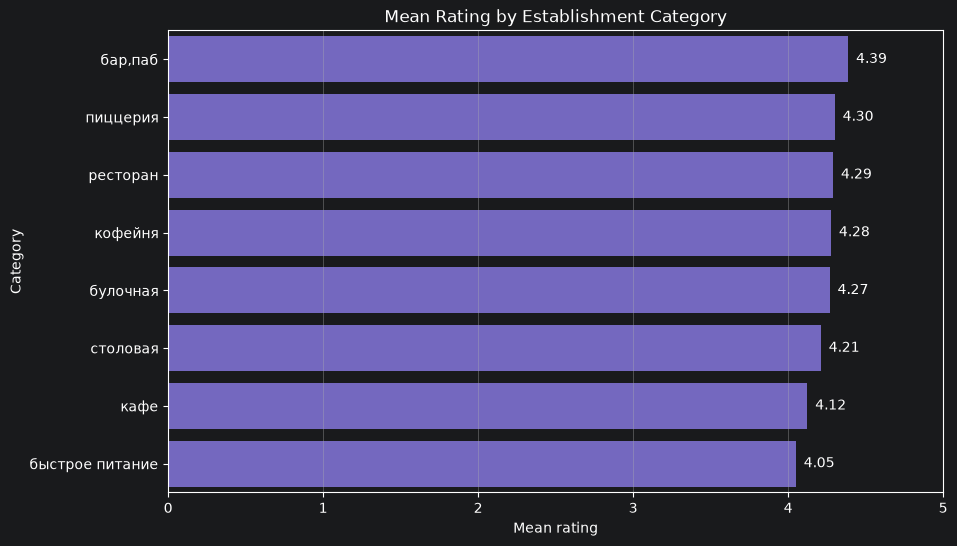

In [47]:
plt.figure(figsize=(10, 6))

plot_data = (
    df.groupby('category')['rating']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

ax = sns.barplot(
    data=plot_data,
    x='rating',
    y='category',
    color='slateblue',
    orient='h'
)

for i, row in plot_data.iterrows():
    ax.text(
        x=row['rating'] + 0.05,
        y=i,
        s='{:.2f}'.format(row['rating']),
        va='center',
        fontsize=10
    )

plt.title('Mean Rating by Establishment Category')
plt.xlabel('Mean rating')
plt.ylabel('Category')
plt.xlim(0, 5.0)
plt.grid(axis='x')
plt.show()

**Insight.**
* **Top Performers:** Bars and pubs (`бар,паб`) achieve the highest average rating across the market at **4.39**, likely reflecting strong experiential loyalty and evening leisure positioning.
* **Core Pack:** Pizzerias (4.30), restaurants (4.29), coffee shops (4.28), bakeries (4.27), and canteens (4.21) cluster tightly around the citywide median.
* **Underperformers:** General cafes (`кафе`, **4.12**) and fast-food outlets (`быстрое питание`, **4.05**) sit at the bottom of the ranking. Although the absolute gap between bars (4.39) and fast food (4.05) is 0.34 points, relative to the 0.30 IQR this represents a shift from the upper tier to the boundary of negative outliers.

---

### 6.6 Multivariate Association Analysis ($\phi_k$ Correlation)

To assess the strength of associations between business attributes and customer ratings (`rating`), a $\phi_k$ (`phik`) correlation matrix is computed for establishments with known price categories (`price != 'unknown'`).

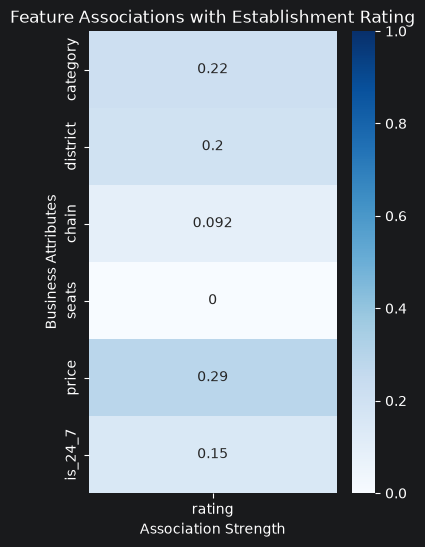

In [48]:
df_clean = df[df['price'] != 'unknown']

features = [
    'rating',
    'category',
    'district',
    'chain',
    'seats',
    'price',
    'is_24_7'
]

phik_matrix = df_clean[features].phik_matrix(interval_cols=['rating', 'seats'])

rating_corr = phik_matrix[['rating']].drop(index='rating')

plt.figure(figsize=(4, 6))

sns.heatmap(
    rating_corr,
    annot=True,
    cmap='Blues',
    vmin=0,
    vmax=1
)

plt.title('Feature Associations with Establishment Rating')
plt.ylabel('Business Attributes')
plt.xlabel('Association Strength')
plt.show()

**Insight.**
* **Overall Association Strength:** All business characteristics exhibit weak-to-moderate associations with `rating` ($\phi_k \le 0.29$), confirming that customer satisfaction depends heavily on execution quality (food, service, hygiene) rather than structural tags alone.
* **Primary Structural Correlates:** Price tier (`price`, $\phi_k = 0.29$) and venue category (`category`, $\phi_k = 0.22$) show the strongest associations with user ratings, followed by administrative district (`district`, $\phi_k = 0.14$) and 24/7 operation (`is_24_7`, $\phi_k = 0.11$).
* **Scale Invariance:** Physical seating capacity (`seats`, $\phi_k = 0.00$) and chain status (`chain`, $\phi_k = 0.09$) have virtually zero association with customer ratings.

To further investigate the association between price category (`price`) and rating (`rating`), rating distributions across price tiers are compared using boxplots.

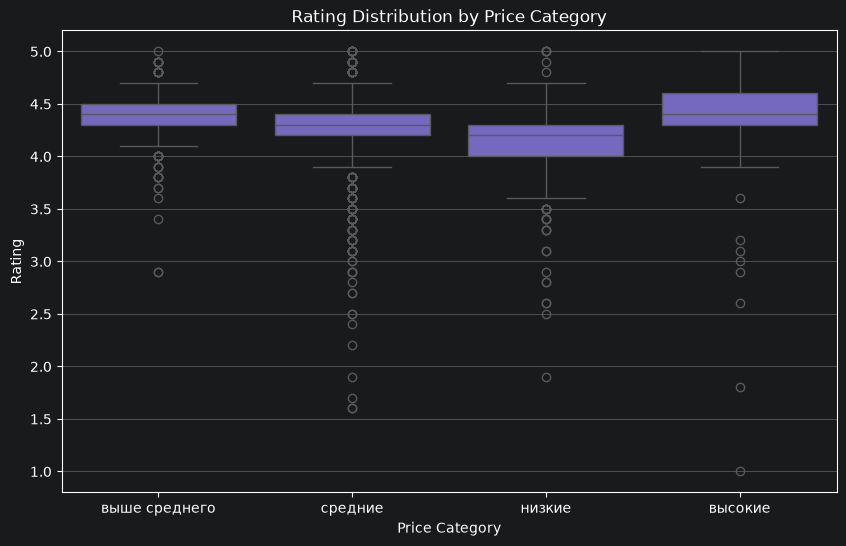

In [49]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='price',
    y='rating',
    color='slateblue'
)

plt.title('Rating Distribution by Price Category')
plt.ylabel('Rating')
plt.xlabel('Price Category')
plt.grid(axis='y')
plt.show()

**Insight.**
* **Positive Price-Rating Gradient:** High-price venues (`высокие`) achieve the highest median rating (~4.4) with the tightest upper-quartile compression, followed closely by upper-middle (`выше среднего`) and mid-tier (`средние`) venues.
* **Budget Tier Penalty:** Low-price venues (`низкие`) exhibit a lower median rating (~4.2) and a noticeably wider downward spread (25th percentile dropping toward 4.0), reflecting higher service variability in high-turnover budget formats.

---

### 6.7 Top-15 Restaurant Chains: Scale vs. Reputation

In [50]:
display(df.groupby('name')['id'].count().sort_values(ascending=False).head(15))

name
Кафе                                   188
Шоколадница                            120
Домино'с Пицца                          76
Додо Пицца                              74
One Price Coffee                        71
Яндекс Лавка                            69
Cofix                                   65
Prime                                   50
Хинкальная                              44
Шаурма                                  43
КОФЕПОРТ                                42
Кулинарная лавка братьев Караваевых     39
Теремок                                 38
Чайхана                                 37
Ресторан                                34
Name: id, dtype: int64

Generic descriptors such as `"Кафе"` (188), `"Хинкальная"` (44), `"Шаурма"` (43), and `"Ресторан"` (34) appear in the raw frequency list because independent operators frequently register generic storefront titles. Filtering strictly to verified chain venues (`chain == 1`) isolates genuine multi-unit brands.

In [51]:
display(df[df['chain'] == 1].groupby('name')['id'].count().sort_values(ascending=False).head(15))

name
Шоколадница                            120
Домино'с Пицца                          76
Додо Пицца                              74
One Price Coffee                        71
Яндекс Лавка                            69
Cofix                                   65
Prime                                   50
Хинкальная                              44
КОФЕПОРТ                                42
Кулинарная лавка братьев Караваевых     39
Теремок                                 38
Чайхана                                 37
CofeFest                                32
Буханка                                 32
Му-Му                                   27
Name: id, dtype: int64

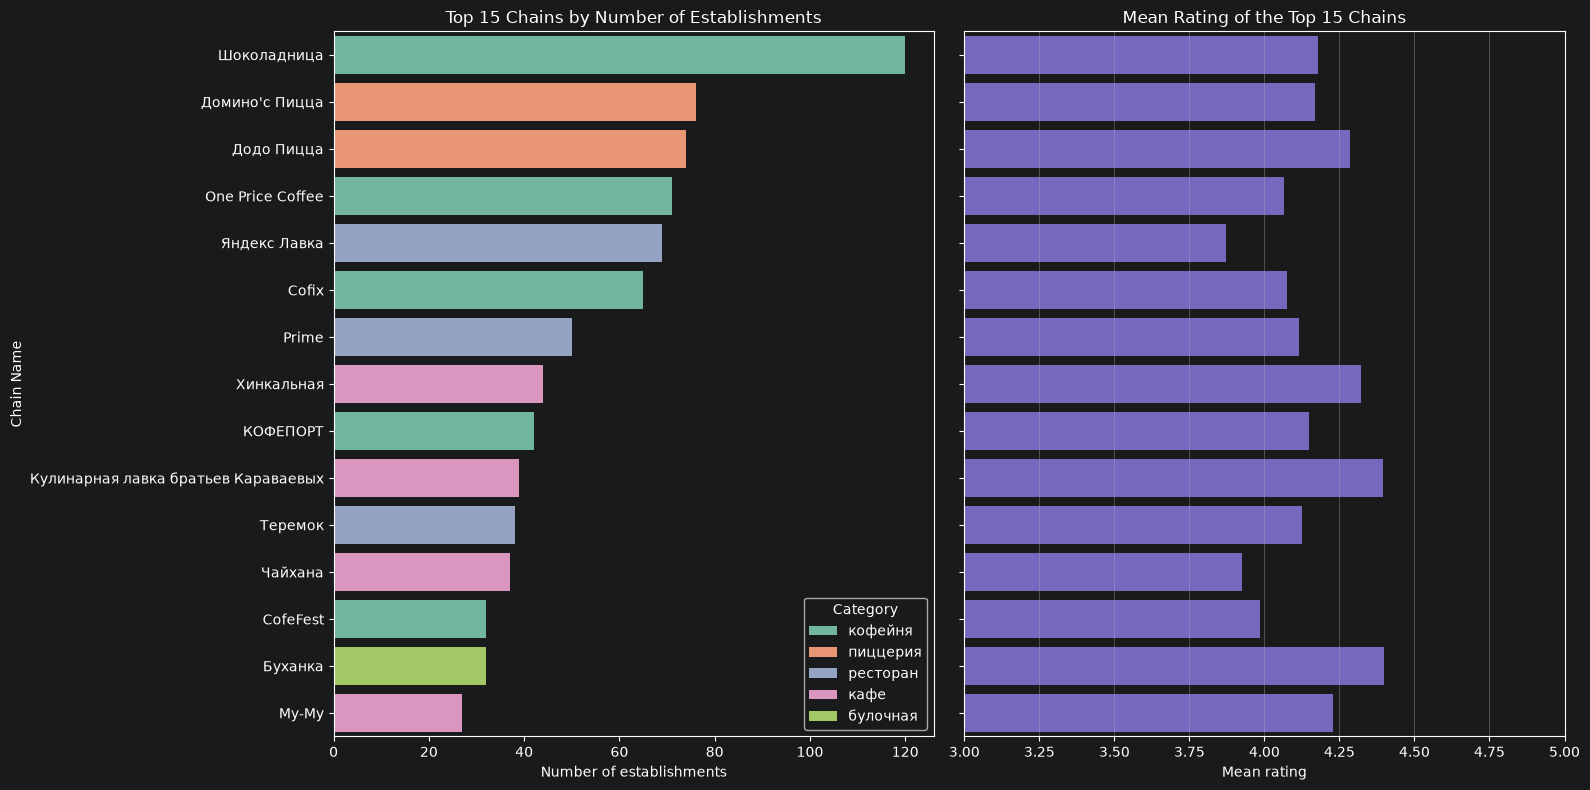

In [52]:
chain_stats = (
    df[df['chain'] == 1].groupby('name')
    .agg(
        count=('name', 'count'),
        avg_rating=('rating', 'mean'),
        # Extract the modal category for each chain to identify its primary format
        category=('category', lambda x: x.mode()[0]) 
    )
    .sort_values(by='count', ascending=False)
    .head(15)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

sns.barplot(
    data=chain_stats,
    x='count',
    y='name',
    hue='category',
    dodge=False,
    ax=axes[0],
    palette='Set2'
)
axes[0].set_title('Top 15 Chains by Number of Establishments')
axes[0].set_xlabel('Number of establishments')
axes[0].set_ylabel('Chain Name')
axes[0].legend(title='Category', loc='lower right')

sns.barplot(
    data=chain_stats,
    x='avg_rating',
    y='name',
    color='slateblue',
    ax=axes[1]
)

axes[1].set_xlim(3.0, 5.0)
axes[1].set_title('Mean Rating of the Top 15 Chains')
axes[1].set_xlabel('Mean rating')
axes[1].set_ylabel('')

plt.grid(axis='x')
plt.tight_layout()
plt.show()

**Insight.**
* **Coffee & Fast-Casual Dominance:** Moscow's largest chains are led by *Shokoladnitsa* (`Шоколадница`, 120 locations), followed by pizza delivery leaders (*Domino's Pizza* with 76, *Dodo Pizza* with 74) and fixed-price/specialty coffee chains (*One Price Coffee* with 71, *Cofix* with 65, *KOFEPORT* with 42, *CofeFest* with 32).
* **Scale Does Not Guarantee Top Ratings:** Market leader *Shokoladnitsa* holds a moderate mean rating (~4.1–4.2), whereas smaller or specialized chains—*Karavaev Brothers Culinary Shop* (`Кулинарная лавка братьев Караваевых`, cafe), *Bukhanka* (`Буханка`, bakery), and *Dodo Pizza* (`Додо Пицца`, pizzeria)—achieve noticeably higher customer ratings (~4.3–4.4+).
* **Directory Categorization Nuances:** *Yandex Lavka* (69 dark-kitchen/delivery hubs) and *Teremok* (38 Russian fast-casual outlets) are categorized under `ресторан` in Yandex Business directory metadata, reflecting self-reported merchant classification.

---

### 6.8 Pricing Landscape and District-Level Bill Comparison

Because `middle_avg_bill` is heavily skewed, the **median average bill** is used to compare pricing levels across Moscow's administrative districts.

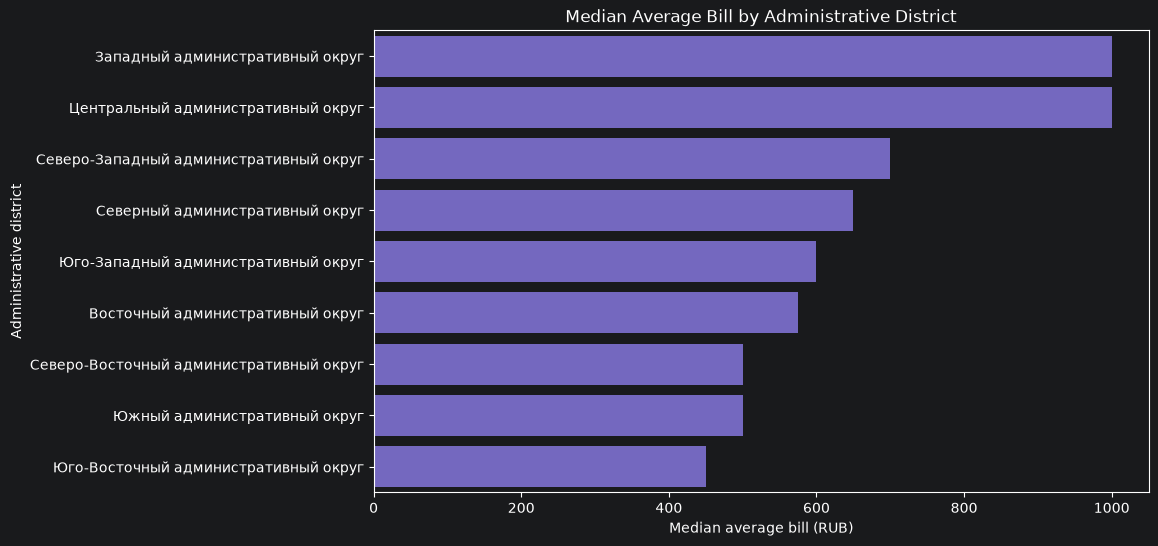

In [53]:
plt.figure(figsize=(10, 6))

median_avg_bill = df.groupby('district')['middle_avg_bill'].median().sort_values(ascending=False)

sns.barplot(
    x=median_avg_bill.values,
    y=median_avg_bill.index,
    color='slateblue',
    orient='h'
)

plt.title('Median Average Bill by Administrative District')
plt.xlabel('Median average bill (RUB)')
plt.ylabel('Administrative district')

plt.show()

**Insight (Testing Hypothesis H4).**
* **ZAO Matches CAO at the Top (~1,000 RUB Median Bill):** Both the Central Administrative District (CAO) and the Western Administrative District (ZAO) lead the city with a median check of ~1,000 RUB. This supports **Hypothesis:** while CAO hosts Moscow's most expensive fine-dining restaurants, its median is moderated by hundreds of high-turnover coffee kiosks and street-food outlets; conversely, ZAO encompasses affluent residential districts (Ramenki, Krylatskoye, Dorogomilovo) where local dining skews toward upper-mid-tier family restaurants.
* **Core Residential Tier (600–800 RUB):** SAO, YUZAO, SZAO, SVAO, VAO, and YUAO form a middle tier with median bills between ~550 and ~800 RUB.
* **Budget Periphery (<500 RUB):** The South-Eastern Administrative District (YUVAO) records the lowest median bill in Moscow (<500 RUB), reflecting a price-sensitive local consumer base.

---

## 7. Conclusions and Limitations

### Answers to the Research Questions
* **RQ1 (Market & Geographic Structure):** Moscow's market is led by cafes (25.4%) and restaurants (24.3%). Over one-fourth of all establishments operate in CAO, where the format mix shifts toward full-service restaurants (~30%) and bars/pubs (~16%) at the expense of budget formats. SZAO is the least saturated district (~5% of venues).
* **RQ2 (Operational Format & Scale):** Chain operations thrive in standardized, process-driven formats (bakeries, pizzerias, coffee shops, fast food), whereas bars/pubs and canteens remain overwhelmingly independent. Observed seating capacities center between 50 and 86 seats depending on category, typically staying under 100 seats.
* **RQ3 (Reputation & Rating Drivers):** User ratings cluster tightly between 4.1 and 4.4 (median 4.30). Bars/pubs achieve the highest mean rating (4.39), whereas fast food (4.05) and cafes (4.12) score lowest. Among major chains, specialized food/bakery brands (*Karavaev Brothers*, *Bukhanka*, *Dodo Pizza*) outperform volume leader *Shokoladnitsa* in customer ratings. Price tier ($\phi_k = 0.29$) and category ($\phi_k = 0.22$) are the top structural correlates of ratings.
* **RQ4 (Regional Pricing Power):** The citywide median bill is 750 RUB (IQR: 375–1,250 RUB). ZAO achieves pricing parity with CAO (~1,000 RUB median bill), whereas YUVAO exhibits the lowest pricing power (<500 RUB).

### Limitations
* **Observational Cross-Section:** All relationships (such as the positive association between price tier and rating, $\phi_k = 0.29$) are correlational rather than causal. Raising menu prices without corresponding improvements in culinary and service quality will not increase ratings.
* **Incomplete Financial & Capacity Coverage:** Seating capacity (`seats`) is missing for 43.0% of venues, and raw financial metrics (`avg_bill`, `middle_avg_bill`) are missing for 54.6%–62.5% of venues. Category medians reflect observed subsamples and may under-represent small non-reporting kiosks.
* **Crowd-Sourced Directory Artifacts:** Yandex Business records rely on merchant self-reporting and automated parsing, introducing categorization nuances (e.g., dark kitchens labeled as restaurants) and mall-capacity assignment artifacts (mitigated in Section 4.3).
* **Static Snapshot & Missing Unit Economics:** Data reflects Summer 2022 and omits commercial rent, pedestrian foot traffic, customer acquisition cost, and operating margins.

---

## 8. Next Steps and Strategic Recommendations

1. **Validate Niche Format Demand Before Entry (Bakeries & Canteens):** The small footprint of bakeries (~3.0%) and canteens (~3.5%) could indicate either an underserved market gap or low standalone unit economics. Conduct localized consumer demand and foot-traffic audits before launching in these segments.
2. **Evaluate SZAO and ZAO for Targeted Geographic Expansion:**
   * **SZAO (Low Competition):** Holds the lowest venue share (~5%) in Moscow. Pair this finding with residential density and transit-hub foot-traffic data to identify underserved micro-locations.
   * **ZAO (High Pricing Power, Moderate Competition):** Matches CAO's ~1,000 RUB median bill with less than half of CAO's competitive density, making it highly attractive for upper-mid-tier restaurants and specialty concepts.
3. **Differentiate Sharply If Entering CAO or Mass Formats:** Launching a cafe or restaurant in CAO means entering the most saturated segment of Moscow's most crowded district. Entry requires a defensible niche concept and strong capitalization.
4. **Match Ownership Model to Format Economics:** Investors seeking multi-unit franchise or chain scalability should target standardized formats (**bakery, pizzeria, coffee shop, fast-casual**). Investors planning a single flagship venue with high rating potential should consider **experiential bar/pub or gastro-concept formats**, where independents dominate and mean ratings are highest (4.39).
5. **Use ~50–85 Seats as an Initial Sizing Baseline, Not a Rigid Rule:** While observed medians fall between 50 seats (bakeries/pizzerias) and 86 seats (restaurants), wide interquartile ranges and 43% missingness mean physical sizing must be anchored to local lease economics and target table turnover.
6. **Calibrate Menu Pricing to District Purchasing Power:** Avoid applying citywide price averages uniformly. Concepts entering price-sensitive districts such as **YUVAO** (median bill <500 RUB) must engineer leaner cost structures and accessible price points compared to CAO or ZAO (~1,000 RUB).
7. **Prioritize Operational Quality Over Structural Tags:** Because structural attributes explain only a modest share of rating variance ($\phi_k \le 0.29$), consistent execution—ingredient quality, service speed, and atmosphere—remains the decisive driver of customer retention, especially in high-risk rating categories like cafes and fast food.